# 💊 Forecasting de unidades - OTC Health Solutions (OTCHS)

## Integrantes:

- Juan Jose Campos Valderrama
- Miguel Delgado Arias 

## Nota sobre los datos

Los datos de este parcial provienen de una empresa farmacéutica estadounidense. Los identificadores de productos y centros de distribución fueron anonimizados, y su uso en este curso es exclusivamente académico.

---

## Contexto e introducción

Una compañía farmacéutica estadounidense comercializa un portafolio de productos de venta libre agrupado en el segmento **OTCHS (Over The Counter Health Solutions)**: analgésicos, antigripales, digestivos, vitaminas y otros productos de cuidado personal que el consumidor compra sin fórmula médica 💊. Estos productos se despachan semanalmente desde varios **centros de distribución (CD)** hacia farmacias y cadenas minoristas en todo el país 🚚.

El área de *Demand Planning* construye hoy sus pronósticos con reglas simples (promedios de las últimas semanas) y sus resultados se revisan **trimestralmente** en el comité de S&OP (*Sales & Operations Planning*). En ese comité los errores de pronóstico se convierten en sobrecostos de inventario o en quiebres de stock, y el negocio necesita reducirlos 📉.

La demanda de estos productos trae varios retos: estacionalidad (p. ej., temporada de gripa y alergias), picos asociados a los ciclos de pedido de los clientes, productos que entran o salen del portafolio, semanas sin pedidos y diferencias de volumen grandes entre centros de distribución. Por eso es indispensable hacer un análisis exploratorio cuidadoso antes de modelar 🧠.

## 🧩 Enunciado

Como consultor externo, se le solicita desarrollar un **modelo predictivo de unidades vendidas** para los SKUs del segmento OTCHS, generando **pronósticos semanales** cuyo desempeño se evaluará a una granularidad **semanal (la semana inicia los domingos)** pero la planeación se hace **por trimestre calendario**. Los datos se encuentran en el archivo `OTCHS_SKUs_History.csv`, que incluye:

- **DC_ID**: código del centro de distribución.
- **SKU_NBR**: código del producto (SKU).
- **ORDER_DATE**: semana del pedido (fecha del domingo que identifica la semana).
- **ITEMS_QTY**: unidades pedidas en esa semana.

El nivel de pronóstico requerido es **SKU × centro de distribución**. Además, deben reportar los resultados agregados por SKU y para el total del segmento.

El objetivo es entregar pronósticos que **mejoren el error trimestral** frente al método actual y que apoyen la planeación de inventarios, producción y distribución. 📊🤝

In [1]:
import pandas as pd
data = pd.read_csv("OTCHS_SKUs_History.csv", delimiter=',', encoding="utf8")
data.head(100)

,DC_ID,SKU_NBR,ORDER_DATE,ITEMS_QTY
0,OR,531343,2026-05-24,489
1,BV,444797,2025-06-15,484
2,MA,520577,2026-05-10,765
3,BV,448404,2024-06-23,525
4,KC,448404,2025-11-23,1211
...,...,...,...,...
95,OR,309433,2025-06-08,2301
96,KC,241483,2024-01-14,717
97,OR,309433,2025-11-30,6716
98,OR,956360,2025-01-19,1541


# ✅ Criterios de evaluación – Descripción

1) **Exploración y limpieza de los datos**  
Exploren la estructura del panel (número de SKUs, centros de distribución, semanas, series completas e incompletas) y el comportamiento de la demanda: tendencia, estacionalidad, picos, valores atípicos, ceros y faltantes, tanto en el total como por CD y por SKU. Estandaricen formatos (fechas, tipos de dato, frecuencia semanal), completen el calendario de cada serie y documenten cada decisión de limpieza (cómo tratan los ceros, las semanas faltantes, los atípicos y las series cortas o nuevas). El resultado es un conjunto de datos listo para modelar.

2) **Modelo base, métrica y separación temporal**  
Implementen **al menos dos modelos base**: **Naive** (última semana, o *seasonal naive*), **Media móvil** y **SARIMA**. Definan una separación entrenamiento/prueba que respete la temporalidad y que tenga como prueba **al menos un trimestre calendario completo** (13 semanas), sin fuga de información. Evalúen con métricas coherentes con el negocio en dos niveles:
   

3) **Pool de modelos para mejorar el modelo base**  
Construyan un **pool de al menos tres modelos avanzados** y comparen su desempeño contra el benchmark, usando **la misma ventana de evaluación y las mismas métricas**. Algunas opciones:
   - **Prophet** (con estacionalidades y/o festivos de EE. UU.).
   - **Nixtla**: `statsforecast` (AutoETS, AutoARIMA, MSTL, Croston/TSB para demanda intermitente), `mlforecast` (LightGBM/XGBoost con rezagos y variables de calendario), `neuralforecast` (NHITS, NBEATS, etc.) o TimeGPT.
   - **Chronos** (Amazon) u otros modelos fundacionales para series de tiempo.
   
   Presenten una tabla comparativa con todos los modelos (base y avanzados), justifiquen la elección de cada uno y analicen dónde mejora cada modelo y dónde no (por CD, por volumen del SKU, por tipo de serie). Se valora usar validación con origen móvil (*rolling forecast*) sobre varios trimestres.

4) **Uso de los modelos: pronóstico semanal y cierre trimestral**  
Seleccionen el modelo o la combinación ganadora y reentrénenla con toda la historia disponible. Generen un **pronóstico semanal** desde la semana siguiente al último dato hasta el **cierre del cuarto trimestre de 2026** (horizonte multipaso). Entreguen:
   - Una tabla de predicciones semanales por SKU × CD, idealmente con intervalos de predicción.
   - El cierre esperado de **Q3 2026** (datos reales observados + semanas pronosticadas) y el total de **Q4 2026**, por SKU y para el total del segmento.
   - Gráficos del horizonte de pronóstico (al menos el total y algunos SKUs representativos).
   - La mejora esperada en el error trimestral frente al método actual (media móvil) y una breve guía para reproducir el proceso cada semana.

**NOTA:** NO olviden generar muchos gráficos para entender mejor los datos a los que se enfrentan

### Punto 1

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (14, 4), "axes.grid": True, "grid.alpha": .3})

data = pd.read_csv("OTCHS_SKUs_History.csv")
data["ORDER_DATE"] = pd.to_datetime(data["ORDER_DATE"])
data["DC_ID"] = data["DC_ID"].astype(str).str.strip()
data["SKU_NBR"] = data["SKU_NBR"].astype(str)

print(data.shape, "| nulos:", data.isna().sum().sum(), "| negativos:", (data.ITEMS_QTY < 0).sum(), "| ceros:", (data.ITEMS_QTY == 0).sum())
print("fechas que no son domingo:", (data.ORDER_DATE.dt.dayofweek != 6).sum(),
      "| llaves duplicadas:", data.duplicated(["DC_ID", "SKU_NBR", "ORDER_DATE"]).sum())
print(f"{data.ORDER_DATE.min().date()} -> {data.ORDER_DATE.max().date()} | CDs: {data.DC_ID.nunique()} | SKUs: {data.SKU_NBR.nunique()} | series SKU x CD: {len(data[['DC_ID','SKU_NBR']].drop_duplicates())}")

(49986, 4) | nulos: 0 | negativos: 0 | ceros: 879
fechas que no son domingo: 0 | llaves duplicadas: 0
2023-12-31 -> 2026-08-30 | CDs: 4 | SKUs: 171 | series SKU x CD: 363


RESULTADO:
- LA BASE CUENTA CON 49 986 FILAS, 140 SEMANAS, 4 CDS, 171 SKU Y 363 SERIES SKU POR CD.
- SE VERIFICO QUE NO EXISTEN NULOS, VALORES NEGATIVOS NI REGISTROS DUPLICADOS, Y QUE CADA FECHA CORRESPONDE A UN DOMINGO.

### DECISION 1, FORMATO Y LIMPIEZA
- SE DECIDIO CONVERTIR SKU_NBR A TEXTO Y ORDER_DATE A TIPO FECHA.
- LOS 879 CEROS, DISTRIBUIDOS EN 145 SERIES, NO SE BORRAN, YA QUE REPRESENTAN SEMANAS EN LAS QUE NO HUBO PEDIDO Y SACARLOS HARIA QUE EL PRONOSTICO QUEDARA INFLADO.

In [3]:
data = data.groupby(["DC_ID", "SKU_NBR", "ORDER_DATE"], as_index=False)["ITEMS_QTY"].sum()   # duplicados -> suma
data["ITEMS_QTY"] = data["ITEMS_QTY"].clip(lower=0)                                          # negativos -> 0

fin = data.ORDER_DATE.max()
partes = []
for (dc, sku), g in data.groupby(["DC_ID", "SKU_NBR"]):
    s = g.set_index("ORDER_DATE")["ITEMS_QTY"]
    s = s.reindex(pd.date_range(s.index.min(), fin, freq="7D"), fill_value=0)   # desde su 1ª venta hasta hoy
    partes.append(pd.DataFrame({"DC_ID": dc, "SKU_NBR": sku, "ORDER_DATE": s.index, "y": s.values}))
panel = pd.concat(partes, ignore_index=True)

print("filas originales:", len(data), "| filas tras completar calendario:", len(panel), "| semanas añadidas:", len(panel) - len(data))
print("semanas por trimestre (domingo de inicio):", panel.groupby(panel.ORDER_DATE.dt.to_period("Q")).ORDER_DATE.nunique().to_dict())

filas originales: 49986 | filas tras completar calendario: 49986 | semanas añadidas: 0


semanas por trimestre (domingo de inicio): {Period('2023Q4', 'Q-DEC'): 1, Period('2024Q1', 'Q-DEC'): 13, Period('2024Q2', 'Q-DEC'): 13, Period('2024Q3', 'Q-DEC'): 13, Period('2024Q4', 'Q-DEC'): 13, Period('2025Q1', 'Q-DEC'): 13, Period('2025Q2', 'Q-DEC'): 13, Period('2025Q3', 'Q-DEC'): 13, Period('2025Q4', 'Q-DEC'): 13, Period('2026Q1', 'Q-DEC'): 13, Period('2026Q2', 'Q-DEC'): 13, Period('2026Q3', 'Q-DEC'): 9}


RESULTADO:
- DESDE LA PRIMERA VENTA HASTA EL ULTIMO REGISTRO NO HAY HUECOS, NINGUNA SEMANA FALTA.
- TODO TRIMESTRE COMPLETO TIENE 13 SEMANAS, MIENTRAS QUE Q3 DE 2026 APENAS LLEVA 9.

### DECISION 2, CALENDARIO
- MIENTRAS NO SE HAYA DADO SU PRIMERA VENTA, EL SKU SE CONSIDERA INEXISTENTE EN ESE CENTRO, POR LO TANTO ESE TRAMO NO SE LLENA CON CEROS.
- SE DECIDIO ASIGNAR CADA SEMANA AL TRIMESTRE EN EL QUE CAE SU DOMINGO, DE ESTA FORMA TODOS LOS TRIMESTRES COMPLETOS QUEDAN COMPARABLES CON 13 SEMANAS CADA UNO.

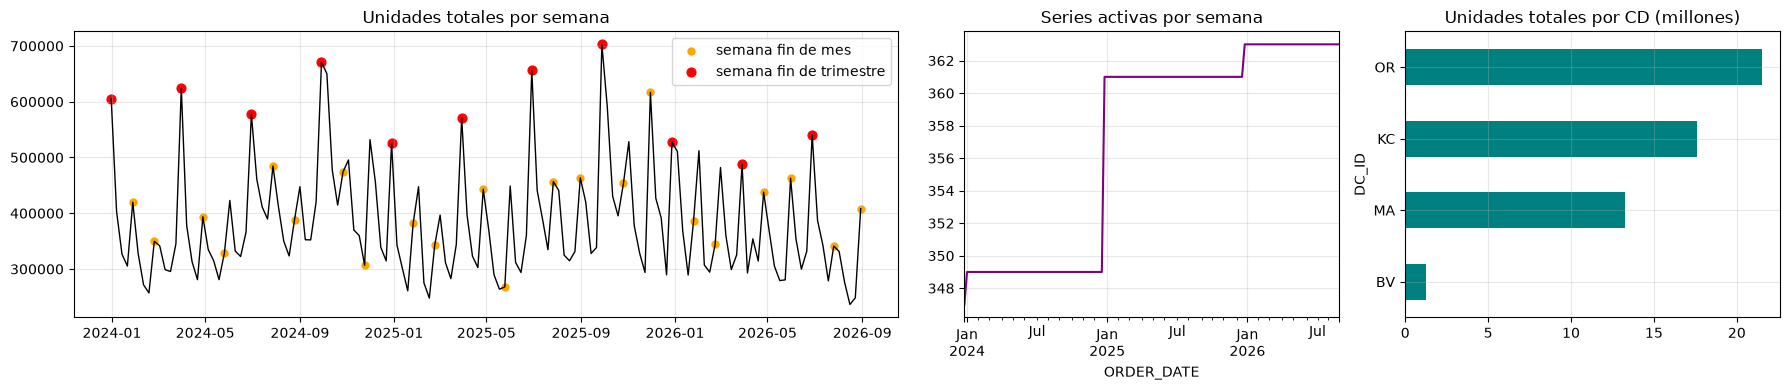

In [4]:
def marcas_calendario(f):
    """Semana (dom-sáb) que contiene el último día del mes / del trimestre. Reutilizable para fechas futuras."""
    f = pd.DatetimeIndex(f)
    fin_mes = (f + pd.offsets.MonthEnd(0) - f).days <= 6
    return pd.DataFrame({"fin_mes": fin_mes, "fin_trim": fin_mes & f.month.isin([3, 6, 9, 12])}, index=f)

cal = marcas_calendario(panel.ORDER_DATE)
panel["fin_mes"], panel["fin_trim"] = cal.fin_mes.values, cal.fin_trim.values
panel["trimestre"] = panel.ORDER_DATE.dt.to_period("Q").astype(str)

tot = panel.groupby("ORDER_DATE").y.sum(); m = marcas_calendario(tot.index)
fig, ax = plt.subplots(1, 3, figsize=(18, 4), gridspec_kw={"width_ratios": [2.2, 1, 1]})
ax[0].plot(tot, color="black", lw=1)
ax[0].scatter(tot.index[m.fin_mes & ~m.fin_trim], tot[m.fin_mes & ~m.fin_trim], c="orange", s=25, label="semana fin de mes")
ax[0].scatter(tot.index[m.fin_trim], tot[m.fin_trim], c="red", s=40, label="semana fin de trimestre")
ax[0].set_title("Unidades totales por semana"); ax[0].legend()
panel.groupby("ORDER_DATE").size().plot(ax=ax[1], color="purple", title="Series activas por semana")
(panel.groupby("DC_ID").y.sum() / 1e6).sort_values().plot.barh(ax=ax[2], color="teal", title="Unidades totales por CD (millones)")
plt.tight_layout(); plt.show()

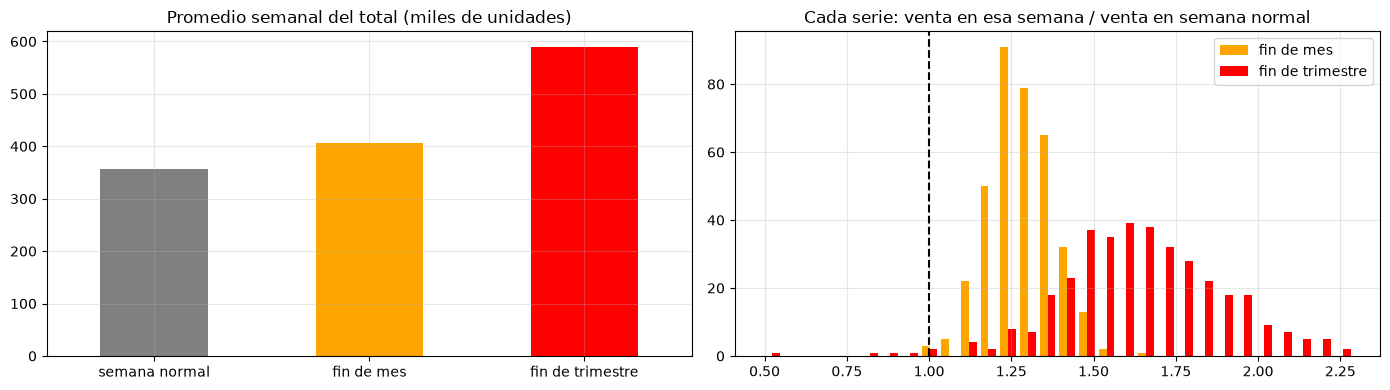

mediana de series: fin de mes = 1.28x | fin de trimestre = 1.63x
pico de fin de mes segun el mes (veces la semana normal): {1: 1.15, 2: 1.06, 3: 1.65, 4: 1.29, 5: 1.14, 6: 1.69, 7: 1.12, 8: 1.29, 9: 1.81, 10: 0.94, 11: 1.17, 12: 1.41}


In [5]:
cat = np.select([tot.index.isin(tot.index[m.fin_trim]), m.fin_mes.values], ["fin de trimestre", "fin de mes"], "semana normal")
med = tot.groupby(cat).mean() / 1e3
r = panel.groupby(["DC_ID", "SKU_NBR", "fin_mes"]).y.mean().unstack(); r_mes = r[True] / r[False]
r = panel.groupby(["DC_ID", "SKU_NBR", "fin_trim"]).y.mean().unstack(); r_trim = r[True] / r[False]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
med.reindex(["semana normal", "fin de mes", "fin de trimestre"]).plot.bar(ax=ax[0], color=["gray", "orange", "red"], rot=0, title="Promedio semanal del total (miles de unidades)")
ax[1].hist([r_mes.dropna(), r_trim.dropna()], bins=30, label=["fin de mes", "fin de trimestre"], color=["orange", "red"])
ax[1].axvline(1, color="k", ls="--"); ax[1].legend(); ax[1].set_title("Cada serie: venta en esa semana / venta en semana normal")
plt.tight_layout(); plt.show()
print(f"mediana de series: fin de mes = {r_mes.median():.2f}x | fin de trimestre = {r_trim.median():.2f}x")
pm = tot.groupby([tot.index.month, m.fin_mes.values]).mean().unstack()          # si fuera clima, el pico seguiria la temperatura y no el cierre
print("pico de fin de mes segun el mes (veces la semana normal):", (pm[True] / pm[False]).round(2).to_dict())

RESULTADO:
- PARA LA SERIE MEDIANA, LA SEMANA QUE CIERRA EL MES REGISTRA 1,28 VECES LA VENTA DE UNA SEMANA COMUN, Y LA QUE CIERRA EL TRIMESTRE 1,63 VECES.
- A NIVEL TOTAL EL SALTO MAS NOTORIO SE DA AL CERRAR EL TRIMESTRE, CON 1,65 EN MARZO, 1,69 EN JUNIO, 1,81 EN SEPTIEMBRE Y 1,41 EN DICIEMBRE, CUANDO LOS OTROS MESES OSCILAN ENTRE 0,94 Y 1,29.

LECTURA DE NEGOCIO:
- NO PARECE QUE EL PICO LO CAUSE EL CLIMA, PUES LA TEMPERATURA VARIA DE FORMA GRADUAL Y NO GENERA UN SALTO CONCENTRADO EN LA SEMANA DEL CIERRE, ADEMAS SU INTENSIDAD ES LA MISMA EN MARZO Y JUNIO QUE EN SEPTIEMBRE.
- LA EXPLICACION MAS LOGICA ES COMERCIAL, CLIENTES QUE JUNTAN SUS ORDENES PARA ALCANZAR METAS O CAPTURAR DESCUENTOS DEL TRIMESTRE, ESTO QUEDA COMO HIPOTESIS QUE DEBE CONFIRMAR EL AREA COMERCIAL.
- EN LA SEMANA FINAL DEL TRIMESTRE SE NECESITA MAS INVENTARIO Y MAS CAPACIDAD DE DESPACHO, EN CONSECUENCIA UNA PROYECCION PLANA COMO LA DE LA MEDIA MOVIL SUBESTIMA EL CIERRE Y SOBREESTIMA EL RESTO DE SEMANAS.

### DECISION 3, PICOS DE CIERRE
- SE DECIDIO NO TOCAR LOS PICOS, YA QUE OBEDECEN AL CALENDARIO Y POR ENDE SE PUEDEN ANTICIPAR.
- PARA IDENTIFICARLOS SE CREAN LAS MARCAS fin_mes Y fin_trim, QUE SE SABEN CON ANTICIPACION Y SE APROVECHAN EN EL PUNTO 3.

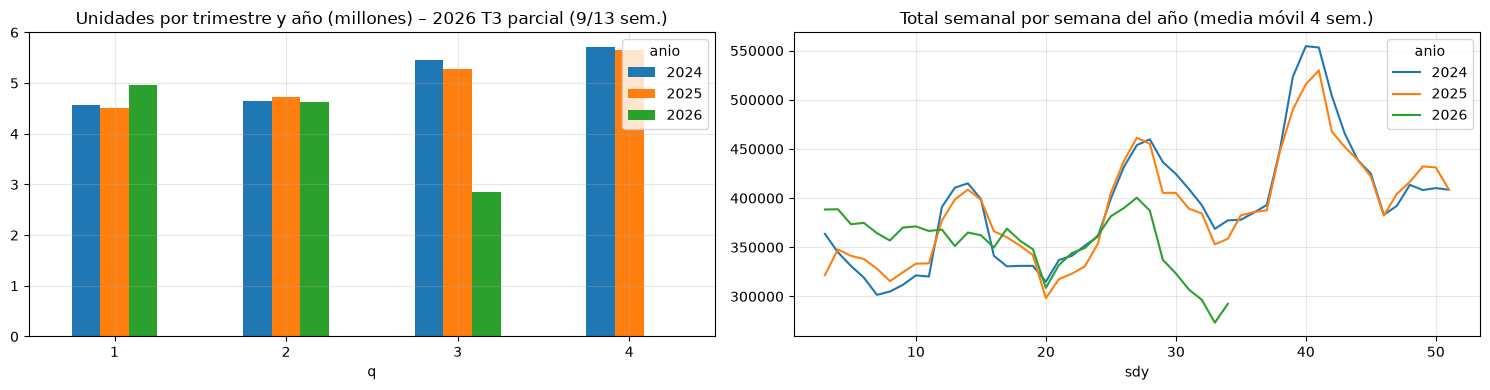

variación interanual por trimestre completo (%): {'2025Q1': -1.3, '2025Q2': 1.8, '2025Q3': -3.3, '2025Q4': -1.1, '2026Q1': 10.2, '2026Q2': -2.2}
primeras 9 semanas del T3 -> 2024: 3.67 M | 2025: 3.50 M | 2026: 2.85 M  (-18.5% vs 2025)
indice mensual 2024-2025 (1 = semana promedio): {1: 0.88, 2: 0.81, 3: 0.98, 4: 0.91, 5: 0.79, 6: 1.05, 7: 1.08, 8: 0.96, 9: 1.15, 10: 1.25, 11: 1.05, 12: 1.09}


In [6]:
q = panel.assign(anio=panel.ORDER_DATE.dt.year, q=panel.ORDER_DATE.dt.quarter).groupby(["anio", "q"]).y.sum().unstack(0).drop(columns=2023) / 1e6
sem = panel.assign(anio=panel.ORDER_DATE.dt.year, sdy=panel.ORDER_DATE.dt.isocalendar().week.astype(int)).groupby(["sdy", "anio"]).y.sum().unstack().drop(columns=2023)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
q.plot.bar(ax=ax[0], rot=0, title="Unidades por trimestre y año (millones) – 2026 T3 parcial (9/13 sem.)")
sem.rolling(4, center=True).mean().plot(ax=ax[1], title="Total semanal por semana del año (media móvil 4 sem.)")
plt.tight_layout(); plt.show()
qt = panel.groupby("trimestre").agg(u=("y", "sum"), n_sem=("ORDER_DATE", "nunique"))
yoy = (qt[qt.n_sem == 13].u.pct_change(4) * 100).round(1)                     # solo trimestres completos
print("variación interanual por trimestre completo (%):", yoy.dropna().to_dict())
t9 = lambda a: tot[(tot.index >= f"{a}-07-01") & (tot.index <= f"{a}-09-30")].iloc[:9].sum()   # primeras 9 semanas del T3
print(f"primeras 9 semanas del T3 -> 2024: {t9(2024)/1e6:.2f} M | 2025: {t9(2025)/1e6:.2f} M | 2026: {t9(2026)/1e6:.2f} M  ({t9(2026)/t9(2025)-1:+.1%} vs 2025)")
im = tot[tot.index.year.isin([2024, 2025])].groupby(lambda f: f.month).mean()   # años completos
print("indice mensual 2024-2025 (1 = semana promedio):", (im / im.mean()).round(2).to_dict())

RESULTADO:
- EL SEGUNDO SEMESTRE (Q3 Y Q4) VENDE MAS QUE EL PRIMERO (Q1 Y Q2), OCTUBRE FUE EL MES MAS FUERTE TANTO EN 2024 COMO EN 2025 (1,25 VECES UNA SEMANA PROMEDIO) Y MAYO EL MAS DEBIL (0,79).
- COMPARADOS CON EL AÑO PREVIO, LOS TRIMESTRES COMPLETOS OSCILAN ENTRE MENOS 3 Y MAS 10 POR CIENTO.
- EN LAS 9 SEMANAS TRANSCURRIDAS DE Q3 DE 2026 LA VENTA ESTA 18,5 POR CIENTO POR DEBAJO DE 2025.

LECTURA DE NEGOCIO:
- EN ESTE CASO EL CLIMA SI PODRIA TENER PESO, PORQUE SE TRATA DE ORDENES DE FARMACIAS Y NO DE COMPRAS DEL CONSUMIDOR FINAL, ENTONCES EL PICO DE SEPTIEMBRE Y OCTUBRE ES COHERENTE CON FARMACIAS QUE SE ABASTECEN ANTES DE QUE LLEGUE EL FRIO Y LA TEMPORADA DE GRIPA (DICIEMBRE A FEBRERO EN ESTADOS UNIDOS), AL NO TENER DATOS DE TEMPERATURA ESTO SE MANTIENE COMO HIPOTESIS.
- PARA Q4 DE 2026 SE ESPERA QUE OCTUBRE SIGA SIENDO EL MES MAS ALTO PERO PARTIENDO DE UN NIVEL INFERIOR, POR LO QUE EL MODELO TIENE QUE RECOGER AL MISMO TIEMPO LA TEMPORADA Y EL DESCENSO RECIENTE.

### DECISION 4, ESTACIONALIDAD
- COMO SOLO SE CUENTA CON 2,7 AÑOS DE DATOS, SE DECIDIO NO INCLUIR UNA ESTACIONALIDAD ANUAL COMPLEJA.
- EL CICLO QUE SE TOMA COMO PRINCIPAL ES EL TRIMESTRAL, DE 13 SEMANAS.

extremos (z>8): 286 filas = 0.57% | 1.10% de las unidades
  caen en semana de fin de mes: 70% (esas semanas son el 24% del calendario)
  atípicos reales (no fin de mes): 85 filas = 0.34% de las unidades


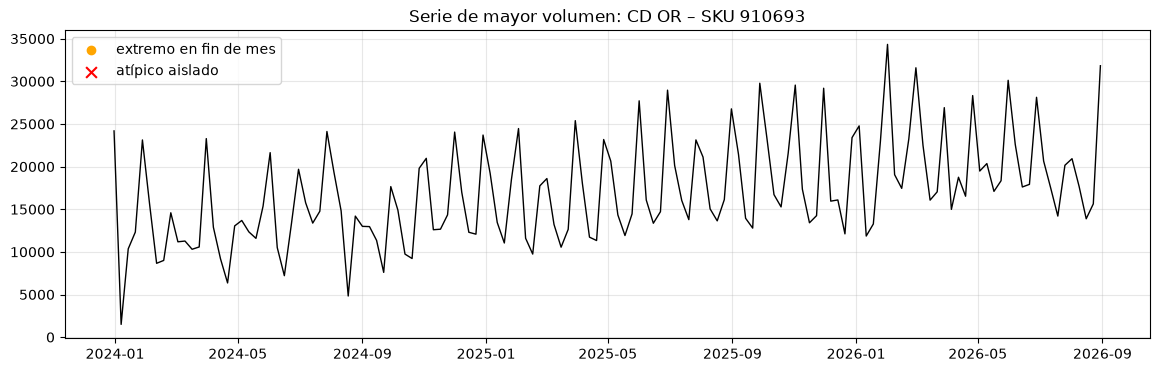

In [7]:
def z_robusto(x):                       # distancia a la mediana móvil de 13 sem. en unidades de MAD
    med = x.rolling(13, center=True, min_periods=5).median()
    mad = (x - med).abs().rolling(13, center=True, min_periods=5).median()
    return (x - med) / (1.4826 * mad.replace(0, np.nan))

panel["z"] = panel.groupby(["DC_ID", "SKU_NBR"]).y.transform(z_robusto)
ext = panel[panel.z > 8]
panel["atipico"] = (panel.z > 8) & ~panel.fin_mes          # extremo Y fuera de semana de cierre
print(f"extremos (z>8): {len(ext)} filas = {len(ext)/len(panel):.2%} | {ext.y.sum()/panel.y.sum():.2%} de las unidades")
print(f"  caen en semana de fin de mes: {ext.fin_mes.mean():.0%} (esas semanas son el {panel.fin_mes.mean():.0%} del calendario)")
print(f"  atípicos reales (no fin de mes): {panel.atipico.sum()} filas = {panel[panel.atipico].y.sum()/panel.y.sum():.2%} de las unidades")

top = panel.groupby(["DC_ID", "SKU_NBR"]).y.sum().idxmax(); s = panel[(panel.DC_ID == top[0]) & (panel.SKU_NBR == top[1])]
plt.figure(figsize=(14, 4)); plt.plot(s.ORDER_DATE, s.y, color="black", lw=1)
plt.scatter(s.ORDER_DATE[s.z > 8], s.y[s.z > 8], c="orange", label="extremo en fin de mes"); plt.scatter(s.ORDER_DATE[s.atipico], s.y[s.atipico], c="red", marker="x", s=60, label="atípico aislado")
plt.title(f"Serie de mayor volumen: CD {top[0]} – SKU {top[1]}"); plt.legend(); plt.show()

RESULTADO:
- LA MAYOR PARTE DE LOS VALORES EXTREMOS, EL 70 POR CIENTO, SE UBICA EN SEMANAS DE CIERRE DE MES.
- LOS ATIPICOS QUE APARECEN AISLADOS SUMAN APENAS 85 FILAS Y EQUIVALEN SOLO AL 0,34 POR CIENTO DE LAS UNIDADES.

### DECISION 5, VALORES ATIPICOS
- SE DECIDIO TRABAJAR CON LA DEMANDA TAL COMO VIENE, DADO QUE CASI TODOS LOS EXTREMOS SON PICOS DE CIERRE Y NO FALLAS EN LOS DATOS.
- POR OTRO LADO, LOS CASOS AISLADOS TIENEN UN PESO TAN BAJO QUE NO ALTERAN EL RESULTADO.

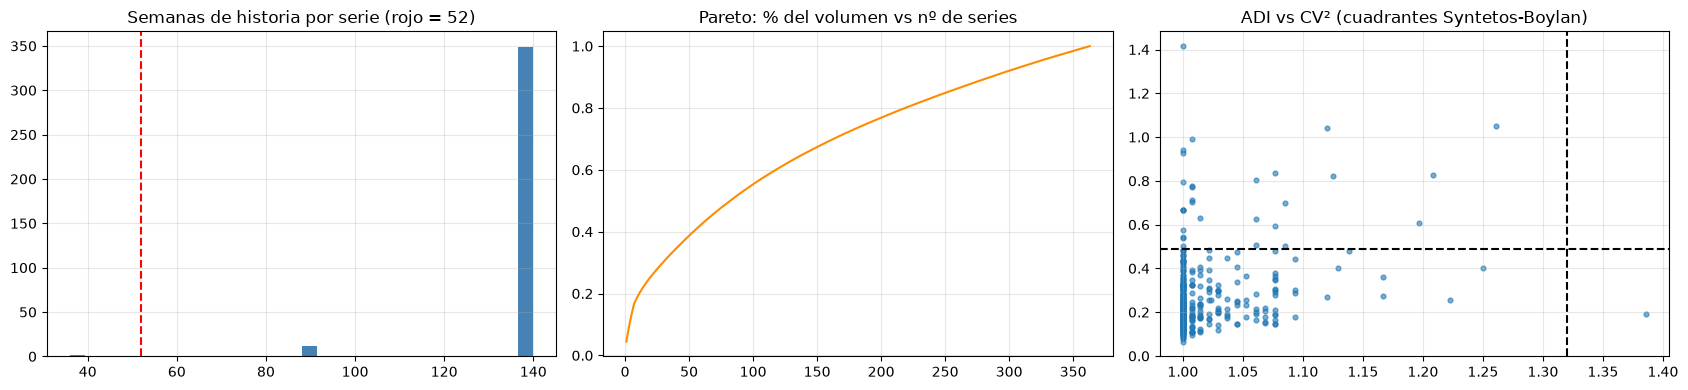

{'smooth': 333, 'erratic': 29, 'intermittent': 1} | ABC: {'A': 219, 'B': 104, 'C': 40} | series cortas: 2
volumen por clase ABC: {'A': 0.8, 'B': 0.15, 'C': 0.049}


In [8]:
k = ["DC_ID", "SKU_NBR"]
info = pd.DataFrame({"n_sem": panel.groupby(k).size(), "total": panel.groupby(k).y.sum(), "pct_ceros": panel.assign(c=panel.y == 0).groupby(k).c.mean()})
nz = panel[panel.y > 0].groupby(k).y
info["adi"] = info.n_sem / nz.size()                          # semanas por cada semana con pedido
info["cv2"] = (nz.std(ddof=0) / nz.mean()) ** 2               # variabilidad del tamaño del pedido
info["clase"] = np.select([(info.adi < 1.32) & (info.cv2 < .49), (info.adi >= 1.32) & (info.cv2 < .49), (info.adi < 1.32) & (info.cv2 >= .49)],
                          ["smooth", "intermittent", "erratic"], "lumpy")
cs = info.total.sort_values(ascending=False).cumsum() / info.total.sum()
info["abc"] = pd.cut(cs.shift(fill_value=0).reindex(info.index), [-1, .8, .95, 1.0001], labels=list("ABC"))
info["corta"] = info.n_sem < 52

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(info.n_sem, bins=30, color="steelblue"); ax[0].axvline(52, color="r", ls="--"); ax[0].set_title("Semanas de historia por serie (rojo = 52)")
ax[1].plot(range(1, len(cs) + 1), cs.values, color="darkorange"); ax[1].set_title("Pareto: % del volumen vs nº de series")
ax[2].scatter(info.adi, info.cv2, s=12, alpha=.6); ax[2].axvline(1.32, color="k", ls="--"); ax[2].axhline(.49, color="k", ls="--"); ax[2].set_title("ADI vs CV² (cuadrantes Syntetos-Boylan)")
plt.tight_layout(); plt.show()
print(info.clase.value_counts().to_dict(), "| ABC:", info.abc.value_counts().to_dict(), "| series cortas:", info.corta.sum())
print("volumen por clase ABC:", (info.groupby("abc", observed=True).total.sum() / info.total.sum()).round(3).to_dict())

RESULTADO:
- 333 SERIES SON DE TIPO SMOOTH (TIENEN PEDIDOS CASI CADA SEMANA Y CON UN TAMAÑO ESTABLE), 29 SON ERRATIC Y SOLO 1 ES INTERMITTENT.
- EL 80 POR CIENTO DEL VOLUMEN SE CONCENTRA EN 219 SERIES, QUE FORMAN LA CLASE A.
- 349 SERIES TIENEN AL MENOS 2 AÑOS DE HISTORIA, 14 SE QUEDAN POR DEBAJO Y LAS 2 MAS CORTAS, UBICADAS EN OR, SUMAN 36 SEMANAS.

### DECISION 6, SEGMENTACION
- NO SE JUSTIFICA UN MODELO ESPECIAL PARA DEMANDA INTERMITENTE, PORQUE UNICAMENTE EXISTE UNA SERIE CON ESE COMPORTAMIENTO.
- LA CLASE ABC Y EL TIPO DE SERIE SE EMPLEAN EN EL PUNTO 3 PARA REVISAR EN QUE SEGMENTOS SE IMPONE CADA MODELO.

In [9]:
# 1. CDS: tamaño, pico de cierre de trimestre y cambio en Q3 2026
w = panel.pivot_table(index="ORDER_DATE", columns="DC_ID", values="y", aggfunc="sum")
mw = marcas_calendario(w.index)
t9_cd = lambda a: w[(w.index >= f"{a}-07-01") & (w.index <= f"{a}-09-30")].iloc[:9].sum()   # primeras 9 semanas del T3
cds = pd.DataFrame({
    "pct_volumen": (w.sum() / w.sum().sum() * 100).round(1),
    "skus": panel.groupby("DC_ID").SKU_NBR.nunique(),
    "pico_fin_trim": (w[mw.fin_trim.values].mean() / w[~mw.fin_mes.values].mean()).round(2),
    "q3_2026_vs_2025_pct": ((t9_cd(2026) / t9_cd(2025) - 1) * 100).round(1),
})
print(cds.sort_values("pct_volumen", ascending=False))
r13 = (panel[panel.ORDER_DATE > fin - pd.Timedelta(weeks=13)].groupby(k).y.sum()
       / panel[(panel.ORDER_DATE > fin - pd.Timedelta(weeks=65)) & (panel.ORDER_DATE <= fin - pd.Timedelta(weeks=52))].groupby(k).y.sum())
print(f"series que venden menos que hace un año (ultimas 13 semanas): {(r13 < 1).mean():.0%} | caen mas de 50%: {(r13 < .5).sum()}")

# 2. CATALOGO: cuando entra cada serie y cual dejo de pedirse
inicio = panel.groupby(k).ORDER_DATE.min()
print("series por semana de entrada:", {str(f.date()): n for f, n in inicio.value_counts().sort_index().items()})
nuevas = inicio[inicio > inicio.min() + pd.Timedelta(weeks=1)].index
a26 = panel[panel.ORDER_DATE.dt.year == 2026]
print(f"volumen 2026 de las series nuevas: {a26[a26.set_index(k).index.isin(nuevas)].y.sum() / a26.y.sum():.1%}")
sin_pedido = panel[panel.ORDER_DATE > fin - pd.Timedelta(weeks=8)].groupby(k).y.sum()
print("series sin pedidos en las ultimas 8 semanas:", sin_pedido[sin_pedido == 0].index.tolist())

       pct_volumen  skus  pico_fin_trim  q3_2026_vs_2025_pct
DC_ID                                                       
OR            40.2   108           1.57                -19.2
KC            32.8   137           1.73                -24.9
MA            24.7   105           1.66                -12.3
BV             2.4    13           2.00                  7.7
series que venden menos que hace un año (ultimas 13 semanas): 74% | caen mas de 50%: 42
series por semana de entrada: {'2023-12-31': 347, '2024-01-07': 2, '2024-12-29': 12, '2025-12-28': 2}
volumen 2026 de las series nuevas: 5.8%
series sin pedidos en las ultimas 8 semanas: [('KC', '171322')]


RESULTADO, CENTROS:
- ENTRE OR Y KC SUMAN EL 73 POR CIENTO DEL VOLUMEN, SIENDO KC EL DE MAYOR CATALOGO (137 SKU).
- BV ES UN CENTRO CHICO (13 SKU, 2,4 POR CIENTO), NO OBSTANTE PRESENTA EL PICO DE CIERRE MAS INTENSO, 2,0 VECES UNA SEMANA COMUN.
- DURANTE Q3 DE 2026 KC RETROCEDE 24,9 POR CIENTO, OR 19,2 Y MA 12,3, MIENTRAS BV CRECE 7,7, AUN ASI LA BAJA ES GENERAL, PUES EL 74 POR CIENTO DE LAS SERIES VENDE MENOS QUE HACE UN AÑO.

RESULTADO, CATALOGO:
- 349 SERIES EXISTEN DESDE EL INICIO DEL PANEL, 12 SE INCORPORAN EL 29 DE DICIEMBRE DE 2024 Y 2 EL 28 DE DICIEMBRE DE 2025, Y ESTAS NUEVAS YA APORTAN EL 5,8 POR CIENTO DEL VOLUMEN DE 2026.
- EL UNICO CASO SIN PEDIDOS EN LAS 8 SEMANAS MAS RECIENTES ES EL SKU 171322 EN KC.

LECTURA DE NEGOCIO:
- EQUIVOCARSE EN OR O KC TIENE UN COSTO DE INVENTARIO MUCHO MAYOR QUE HACERLO EN BV, SIN EMBARGO BV DEBE APARTAR CAPACIDAD PARA SU SEMANA DE CIERRE.
- LOS PRODUCTOS NUEVOS ENTRAN EN LA SEMANA FINAL DEL AÑO, DE REPETIRSE ESE PATRON PODRIAN SURGIR SKU NUEVOS EL 27 DE DICIEMBRE DE 2026, QUE ES LA ULTIMA SEMANA DEL HORIZONTE, Y SIN EL PLAN COMERCIAL NINGUN MODELO PUEDE PREVERLOS.
- CUANDO UNA SERIE DEJA DE TENER PEDIDOS Y EL MODELO LE SIGUE ASIGNANDO UNIDADES, SE CORRE EL RIESGO DE ACUMULAR INVENTARIO OBSOLETO.

### DECISION 7, CENTROS
- SE DECIDIO QUE LOS ERRORES TAMBIEN SE REPORTEN DESAGREGADOS POR CD.
- CADA MODELO DEBE AJUSTARSE AL NIVEL PARTICULAR DE CADA SERIE EN VEZ DE APLICAR UN UNICO AJUSTE A TODO EL SEGMENTO, YA QUE LA CAIDA NO ES IGUAL EN TODOS LOS CENTROS.

### DECISION 8, PRODUCTOS QUE ENTRAN Y SALEN
- LAS SERIES NUEVAS SE MODELAN SOLO DESDE EL MOMENTO DE SU PRIMERA VENTA.
- AL SKU 171322 EN KC SE LE TRATA COMO UN POSIBLE PRODUCTO DESCONTINUADO, ASI QUE SU PRONOSTICO SE VALIDA ANTES DE DESTINARLE INVENTARIO.

In [10]:
panel = panel.join(info[["abc", "clase", "corta"]], on=["DC_ID", "SKU_NBR"]).drop(columns="z")

horizonte = pd.date_range(panel.ORDER_DATE.max() + pd.Timedelta(days=7), "2026-12-27", freq="7D")
print(panel.shape, "| series:", panel.groupby(["DC_ID", "SKU_NBR"]).ngroups, "| última semana:", panel.ORDER_DATE.max().date())
print(f"horizonte: {len(horizonte)} semanas ({horizonte[0].date()} -> {horizonte[-1].date()}) | de ellas en Q3-2026: {(horizonte.to_period('Q') == pd.Period('2026Q3')).sum()}")
panel.head()

(49986, 11) | series: 363 | última semana: 2026-08-30
horizonte: 17 semanas (2026-09-06 -> 2026-12-27) | de ellas en Q3-2026: 4


,DC_ID,SKU_NBR,ORDER_DATE,y,fin_mes,fin_trim,trimestre,atipico,abc,clase,corta
0,BV,108646,2024-12-29,691,True,True,2024Q4,False,C,smooth,False
1,BV,108646,2025-01-05,688,False,False,2025Q1,False,C,smooth,False
2,BV,108646,2025-01-12,486,False,False,2025Q1,False,C,smooth,False
3,BV,108646,2025-01-19,402,False,False,2025Q1,False,C,smooth,False
4,BV,108646,2025-01-26,281,True,False,2025Q1,False,C,smooth,False


## PUNTO 2

## METODOLOGIA
- MODELOS BASE: NAIVE (COPIA EL VALOR DE LA SEMANA MAS RECIENTE), NAIVE ESTACIONAL (TOMA LA MISMA SEMANA DEL AÑO PREVIO), MEDIA MOVIL DE 13 SEMANAS (EL METODO QUE SE USA HOY) Y SARIMA.
- SE DECIDIO VALIDAR CON ORIGEN MOVIL, ES DECIR, EL MODELO APRENDE CON TODA LA INFORMACION PREVIA A UN TRIMESTRE, LO PRONOSTICA Y ESTE PROCESO SE REPITE PARA CADA TRIMESTRE.
- WAPE, SUMA DEL ERROR ABSOLUTO DIVIDIDA ENTRE LA DEMANDA REAL, UN VALOR MAS BAJO INDICA UN MEJOR MODELO.
- SESGO, DIFERENCIA ENTRE PRONOSTICO Y REAL DIVIDIDA ENTRE LA DEMANDA REAL, UN VALOR POSITIVO SIGNIFICA PEDIR DE MAS Y UNO NEGATIVO PEDIR DE MENOS.

 fold     origen test_inicio   test_fin trimestre  n_train  n_test  trimestre_completo  series_activas  series_nuevas  porcentaje_unidades_nuevas
    1 2024-12-29  2025-01-05 2025-03-30    2025Q1       53      13                True             361              2                    0.000000
    2 2025-03-30  2025-04-06 2025-06-29    2025Q2       66      13                True             361              2                    0.000000
    3 2025-06-29  2025-07-06 2025-09-28    2025Q3       79      13                True             361              2                    0.000000
    4 2025-09-28  2025-10-05 2025-12-28    2025Q4       92      13                True             361              2                    0.000438
    5 2025-12-28  2026-01-04 2026-03-29    2026Q1      105      13                True             363              0                    0.000000
    6 2026-03-29  2026-04-05 2026-06-28    2026Q2      118      13                True             363              0       

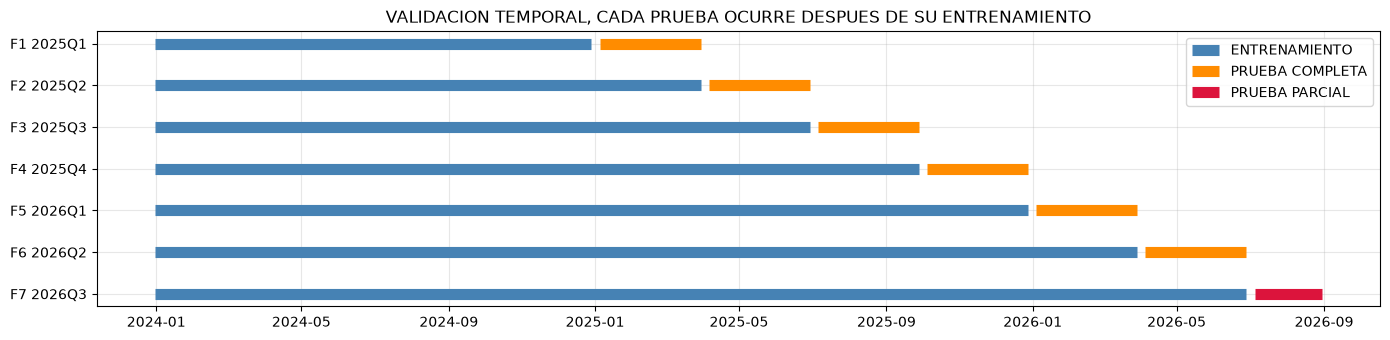

In [11]:
MIN_TRAIN, H_MAX = 52, 13
semanas = pd.date_range(panel.ORDER_DATE.min(), panel.ORDER_DATE.max(), freq="7D")
cal_s = marcas_calendario(semanas)
origenes = [o for o in semanas[cal_s.fin_trim.to_numpy()] if semanas.get_loc(o) + 1 >= MIN_TRAIN]

Y = panel.pivot(index=["DC_ID", "SKU_NBR"], columns="ORDER_DATE", values="y").reindex(columns=semanas)
M = Y.to_numpy(dtype=float)
dcs = Y.index.get_level_values("DC_ID").to_numpy()
skus = Y.index.get_level_values("SKU_NBR").to_numpy()

filas = []
for fold, origen in enumerate(origenes, start=1):
    i = semanas.get_loc(origen)
    horizonte = min(H_MAX, len(semanas) - i - 1)
    activas = ~np.isnan(M[:, i])
    futuras = M[:, i + 1:i + horizonte + 1]
    excluidas = np.nansum(futuras[~activas])
    total = np.nansum(futuras)
    filas.append({
        "fold": fold,
        "origen": origen,
        "test_inicio": semanas[i + 1],
        "test_fin": semanas[i + horizonte],
        "trimestre": str(semanas[i + 1].to_period("Q")),
        "n_train": i + 1,
        "n_test": horizonte,
        "trimestre_completo": horizonte == H_MAX,
        "series_activas": int(activas.sum()),
        "series_nuevas": int((~activas).sum()),
        "porcentaje_unidades_nuevas": excluidas / total if total else np.nan,
        "i_origen": i,
    })
folds = pd.DataFrame(filas)
print(folds.drop(columns="i_origen").to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 3.5))
for f in folds.itertuples():
    ax.hlines(f.fold, semanas[0], f.origen, color="steelblue", linewidth=8,
              label="ENTRENAMIENTO" if f.fold == 1 else None)
    ax.hlines(f.fold, f.test_inicio, f.test_fin,
              color="darkorange" if f.trimestre_completo else "crimson", linewidth=8,
              label="PRUEBA COMPLETA" if f.fold == 1 else ("PRUEBA PARCIAL" if not f.trimestre_completo else None))
ax.set_yticks(folds.fold)
ax.set_yticklabels([f"F{f.fold} {f.trimestre}" for f in folds.itertuples()])
ax.invert_yaxis()
ax.set_title("VALIDACION TEMPORAL, CADA PRUEBA OCURRE DESPUES DE SU ENTRENAMIENTO")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## QUE ES CADA FOLD
- CADA FOLD ES UN EJERCICIO DE PRUEBA, EL MODELO SE ENTRENA CON TODA LA HISTORIA PREVIA AL TRIMESTRE Y LUEGO LO PRONOSTICA SIN HABER VISTO NINGUNO DE SUS DATOS.

| FOLD | TRIMESTRE DE PRUEBA | SEMANAS DE ENTRENAMIENTO |
|---|---|---|
| 1 | Q1 2025 | 53 |
| 2 | Q2 2025 | 66 |
| 3 | Q3 2025 | 79 |
| 4 | Q4 2025 | 92 |
| 5 | Q1 2026 | 105 |
| 6 | Q2 2026 | 118 |
| 7 | Q3 2026, PARCIAL (9 SEMANAS) | 131 |

- LOS FOLDS DEL 1 AL 6 SON TRIMESTRES COMPLETOS, Y SU PROMEDIO ES LO QUE SE USA PARA COMPARAR LOS MODELOS.
- EL FOLD 7 SE PRESENTA APARTE, YA QUE NO ESTA COMPLETO Y ADEMAS ES EL UNICO QUE OCURRE DESPUES DE LA CAIDA DE 2026.
- CONTAR CON MAS HISTORIA NO GARANTIZA UN MENOR ERROR, EL FOLD 7 TIENE LA MAYOR CANTIDAD DE DATOS PERO LA HISTORIA MAS VIEJA REFLEJA UN NIVEL DE DEMANDA QUE YA NO SE OBSERVA EN 2026.
- EN CADA FOLD, LAS SERIES QUE TENGAN MENOS DE 26 SEMANAS DE HISTORIA SE DEJAN POR FUERA EN TODOS LOS MODELOS.

## IDENTIFICACION DEL SARIMA
- SE SIGUE EL PROCEDIMIENTO VISTO EN CLASE (DESCOMPOSICION, PRUEBAS ESTADISTICAS, ACF Y PACF, AIC), TRABAJANDO UNICAMENTE CON LAS 53 SEMANAS QUE ANTECEDEN AL FOLD 1.
- DE ESTA MANERA LA ELECCION DEL ORDEN NO SE CONTAMINA CON NINGUN TRIMESTRE DE PRUEBA.

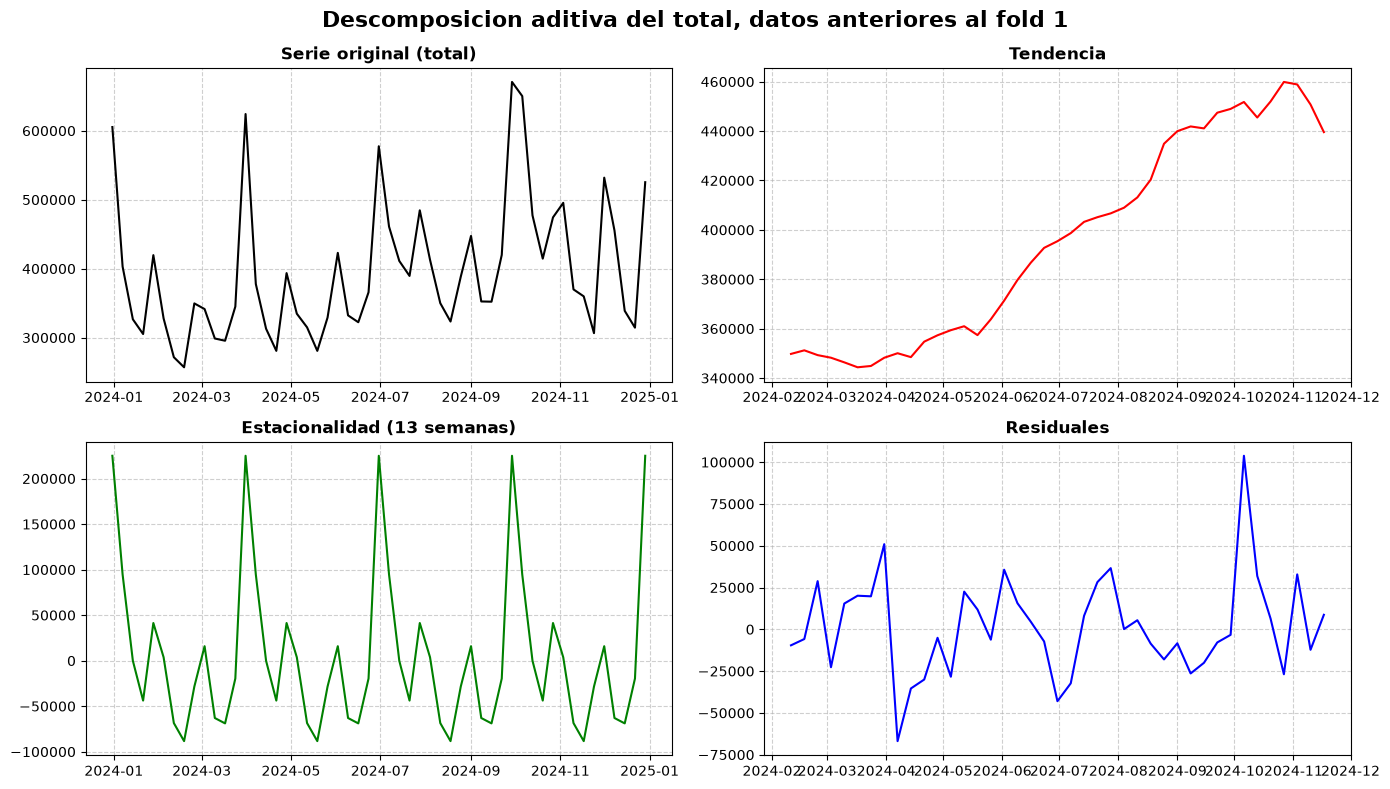

H0: ADF = no estacionaria | ARCH = varianza constante | Ljung-Box = sin autocorrelacion
nivel                        ADF p=0.778 | ARCH p=0.012 | Ljung-Box(13) p=0.000
logaritmo                    ADF p=0.829 | ARCH p=0.001 | Ljung-Box(13) p=0.000
primera diferencia (d=1)     ADF p=0.000 | ARCH p=0.253 | Ljung-Box(13) p=0.000
diferencia estacional (D=1)  ADF p=0.030 | ARCH p=0.865 | Ljung-Box(13) p=0.158


In [12]:
import warnings
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox

ident = tot[tot.index <= folds.origen.iloc[0]]          # total semanal hasta el origen del fold 1
decomp = seasonal_decompose(ident, model="additive", period=13)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
paneles = [(ident, "Serie original (total)", "black"), (decomp.trend, "Tendencia", "red"),
           (decomp.seasonal, "Estacionalidad (13 semanas)", "green"), (decomp.resid, "Residuales", "blue")]
for ax, (serie, titulo, color) in zip(axes.flat, paneles):
    ax.plot(serie, color=color)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.6)
plt.suptitle("Descomposicion aditiva del total, datos anteriores al fold 1", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

def pruebas(x, nombre):
    x = x.dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)   # avisos de cambio de version de statsmodels
        print(f"{nombre:28s} ADF p={adfuller(x)[1]:.3f} | ARCH p={het_arch(x)[1]:.3f} | Ljung-Box(13) p={acorr_ljungbox(x, lags=[13]).lb_pvalue.iloc[0]:.3f}")

print("H0: ADF = no estacionaria | ARCH = varianza constante | Ljung-Box = sin autocorrelacion")
pruebas(ident, "nivel")
pruebas(np.log(ident), "logaritmo")
pruebas(ident.diff(), "primera diferencia (d=1)")
pruebas(ident.diff(13), "diferencia estacional (D=1)")

RESULTADO:
- EN SU NIVEL ORIGINAL EL TOTAL NO ES ESTACIONARIO (ADF p 0,778) Y TOMAR LOGARITMO TAMPOCO LO SOLUCIONA.
- AL APLICAR LA PRIMERA DIFERENCIA SE LOGRA ESTACIONARIEDAD, PERO PERSISTE LA AUTOCORRELACION (LJUNG-BOX p 0,000) PORQUE EL PICO DE CIERRE NO DESAPARECE.
- CON LA DIFERENCIA ESTACIONAL DE 13 SEMANAS SI SE OBTIENE BUEN RESULTADO, LA SERIE QUEDA ESTACIONARIA (ADF p 0,030), CON VARIANZA ESTABLE (ARCH p 0,865) Y LIBRE DE AUTOCORRELACION (LJUNG-BOX p 0,158).

### DECISION 9, DIFERENCIACION
- SE DECIDIO TRABAJAR CON D = 1, s = 13 Y d = 0.
- VISTO DESDE EL NEGOCIO, EL MODELO TOMA COMO PUNTO DE PARTIDA LA MISMA SEMANA DEL TRIMESTRE PREVIO, Y POR ESO SE MANTIENE PEGADO AL NIVEL RECIENTE EN VEZ DE DEVOLVERSE A UN PROMEDIO HISTORICO.

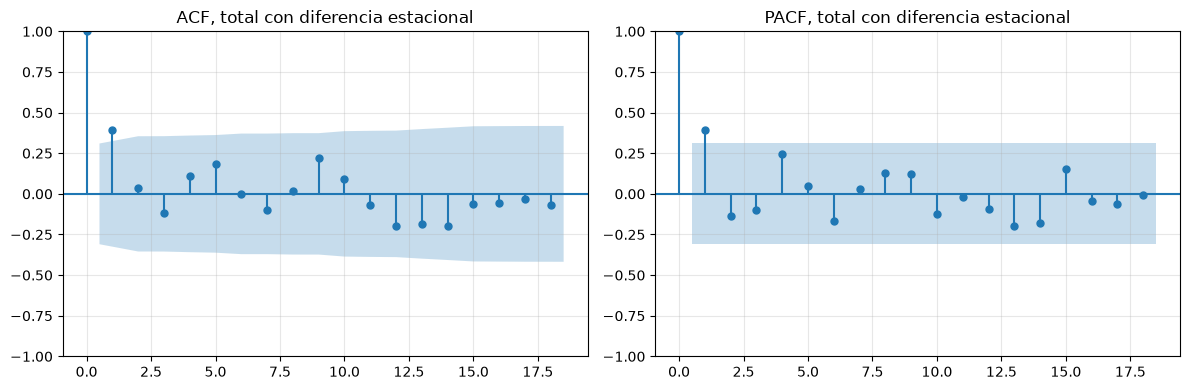

In [13]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

ident_d = ident.diff(13).dropna()                       # total con diferencia estacional
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(ident_d, lags=18, ax=axes[0], title="ACF, total con diferencia estacional")
plot_pacf(ident_d, lags=18, ax=axes[1], title="PACF, total con diferencia estacional")
plt.tight_layout()
plt.show()

RESULTADO:
- UNA VEZ APLICADA LA DIFERENCIA ESTACIONAL, UNICAMENTE EL REZAGO 1 SUPERA LAS BANDAS, TANTO EN EL ACF (0,39) COMO EN EL PACF (0,40), LO CUAL INDICA UN AR(1).
- EN EL PACF LOS REZAGOS 13 Y 14 QUEDAN JUSTO EN EL BORDE, POR LO TANTO LA COMPONENTE ESTACIONAL SE DEFINE MEDIANTE EL AIC.

In [14]:
import itertools
from statsmodels.tsa.statespace.sarimax import SARIMAX

def mejor_orden(y):
    """Busqueda por AIC con d = 0 y D = 1 fijos por las pruebas anteriores."""
    res = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                  # avisos de convergencia de statsmodels
        for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
            r = SARIMAX(y, order=(p, 0, q), seasonal_order=(P, 1, Q, 13)).fit(disp=False)
            res.append({"orden": f"({p},0,{q})({P},1,{Q})13", "aic": round(r.aic, 1)})
    return pd.DataFrame(res).sort_values("aic")

print("TOTAL, 6 MEJORES POR AIC")
print(mejor_orden(ident).head(6).to_string(index=False))

# misma busqueda en 20 series SKU x CD al azar con historia completa antes del fold 1
hist = panel[panel.ORDER_DATE <= folds.origen.iloc[0]].pivot(index="ORDER_DATE", columns=["DC_ID", "SKU_NBR"], values="y").dropna(axis=1)
ganadores = [mejor_orden(hist[c]).orden.iloc[0] for c in hist.sample(20, axis=1, random_state=42)]
print("\nORDEN GANADOR EN 20 SERIES:", pd.Series(ganadores).value_counts().head(5).to_dict())

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    elegido = SARIMAX(ident, order=(1, 0, 0), seasonal_order=(0, 1, 1, 13)).fit(disp=False)
print("\nORDEN ELEGIDO EN EL TOTAL, COEFICIENTES Y P VALOR")
print(pd.DataFrame({"coef": elegido.params, "p_valor": elegido.pvalues}).drop("sigma2").round(3))

TOTAL, 6 MEJORES POR AIC


           orden    aic
(2,0,2)(1,1,0)13  998.7
(1,0,0)(0,1,0)13  998.8
(0,0,1)(0,1,0)13  998.9
(1,0,0)(1,1,0)13  999.8
(2,0,0)(0,1,0)13  999.9
(1,0,1)(0,1,0)13 1000.0



ORDEN GANADOR EN 20 SERIES: {'(1,0,0)(0,1,1)13': 6, '(2,0,0)(1,1,0)13': 2, '(1,0,0)(1,1,0)13': 2, '(1,0,0)(0,1,0)13': 2, '(1,0,2)(0,1,0)13': 2}

ORDEN ELEGIDO EN EL TOTAL, COEFICIENTES Y P VALOR
           coef  p_valor
ar.L1     0.419    0.000
ma.S.L13 -0.061    0.491


RESULTADO:
- PARA EL TOTAL, LOS 6 MEJORES MODELOS SE SEPARAN POR MENOS DE 2 PUNTOS DE AIC, LO QUE EQUIVALE A UN EMPATE.
- SOBRE LAS 20 SERIES, EL ORDEN (1,0,0)(0,1,1)13 RESULTA GANADOR EN 6 CASOS Y NINGUNA OTRA ALTERNATIVA SUPERA LOS 2.
- EN EL TOTAL EL COEFICIENTE AR(1) ES DE 0,42 Y ES SIGNIFICATIVO, LA MEDIA MOVIL ESTACIONAL SALE CASI EN CERO PORQUE A ESE NIVEL LOS PICOS SE REPITEN DE MANERA UNIFORME, EN CAMBIO EN LAS SERIES INDIVIDUALES SI SUMA PORQUE TIENEN MAS RUIDO.

### DECISION 10, ORDEN DEL SARIMA
- SE DECIDIO TRABAJAR CON SARIMA (1,0,0)(0,1,1)13, EL MISMO PARA TODAS LAS SERIES Y PARA TODOS LOS FOLDS.
- LA ELECCION SE BASA EN EL COMPORTAMIENTO DE LAS SERIES SKU POR CD, PUES ESE ES EL NIVEL AL QUE SE GENERA EL PRONOSTICO.

## COMO LEER SARIMA (1,0,0)(0,1,1)13

| PARTE | VALOR | QUE SIGNIFICA |
|---|---|---|
| s | 13 | UN CICLO COMPLETO EQUIVALE A UN TRIMESTRE DE 13 SEMANAS |
| p | 1 | LO QUE SUCEDIO LA SEMANA ANTERIOR AFECTA A LA SEMANA ACTUAL |
| d | 0 | NO SE TOMA LA DIFERENCIA CONTRA LA SEMANA ANTERIOR |
| q | 0 | NO HAY CORRECCION CON EL ERROR DE LA SEMANA PASADA |
| P | 0 | NO SE AÑADE UN SEGUNDO AJUSTE CON EL DATO DE HACE 13 SEMANAS |
| D | 1 | SE MODELA EL CAMBIO FRENTE A LA MISMA SEMANA DEL TRIMESTRE PREVIO |
| Q | 1 | SE AJUSTA CON EL ERROR QUE HUBO HACE 13 SEMANAS |

- RESUMIDO EN UNA FRASE, PRONOSTICO DE LA SEMANA = MISMA SEMANA DEL TRIMESTRE PREVIO + AJUSTE SEGUN EL COMPORTAMIENTO DE LA SEMANA PASADA + CORRECCION POR EL ERROR DE HACE UN TRIMESTRE.
- POR EJEMPLO, EN EL TOTAL: SI LA SEMANA ANTERIOR SE VENDIERON 100 UNIDADES POR ENCIMA DE SU MISMA SEMANA DEL TRIMESTRE PREVIO, PARA LA SEMANA ACTUAL SE ESPERAN 42 UNIDADES POR ENCIMA DE LA SUYA (AR = 0,42), Y ESE IMPACTO SE VA DILUYENDO CON EL PASO DE LAS SEMANAS.

In [15]:
from statsforecast import StatsForecast
from statsforecast.models import ARIMA

ORDEN, ORDEN_EST = (1, 0, 0), (0, 1, 1)                  # DECISION 10
MIN_SARIMA_TRAIN = 26                                    # dos trimestres completos de historia
# method="ML": maxima verosimilitud exacta como SARIMAX de statsmodels, el metodo por defecto falla en 2 series del fold 1
largo = panel[["DC_ID", "SKU_NBR", "ORDER_DATE", "y"]].rename(columns={"ORDER_DATE": "ds"})
largo["unique_id"] = largo.DC_ID + "_" + largo.SKU_NBR
hace_52 = largo[["unique_id", "ds", "y"]].assign(ds=largo.ds + pd.Timedelta(weeks=52)).rename(columns={"y": "snaive"})

pronosticos, cobertura = [], []
for f in folds.itertuples():
    train = largo[largo.ds <= f.origen]
    test = largo[(largo.ds > f.origen) & (largo.ds <= f.test_fin)]
    n_train, n_test = train.groupby("unique_id").size(), test.groupby("unique_id").size()
    ids = n_train.index[n_train >= MIN_SARIMA_TRAIN].intersection(n_test.index[n_test == f.n_test])

    sf = StatsForecast(models=[ARIMA(order=ORDEN, seasonal_order=ORDEN_EST, season_length=13, method="ML", alias="sarima")], freq="W-SUN", n_jobs=1)
    pred = sf.forecast(df=train[train.unique_id.isin(ids)][["unique_id", "ds", "y"]], h=f.n_test)
    pred = test[test.unique_id.isin(ids)].merge(pred, on=["unique_id", "ds"], validate="one_to_one")
    assert len(pred) == len(ids) * f.n_test, "las fechas del pronostico no coinciden con la prueba"

    ultimas = train.groupby("unique_id").y
    pred["ma13"] = pred.unique_id.map(ultimas.apply(lambda s: s.tail(13).mean()))
    pred["naive"] = pred.unique_id.map(ultimas.last())
    pred = pred.merge(hace_52, on=["unique_id", "ds"], how="left")
    pred["snaive"] = pred.snaive.fillna(pred.ma13)       # si la serie no existia hace un año se usa su MA13
    pred["sarima"] = pred.sarima.clip(lower=0)
    pred["fold"], pred["h"] = f.fold, (pred.ds - f.test_inicio).dt.days // 7 + 1
    pronosticos.append(pred)
    cobertura.append({"fold": f.fold, "series_comparadas": len(ids), "unidades_evaluadas": pred.y.sum() / test.y.sum()})

fc = pd.concat(pronosticos).rename(columns={"ds": "ORDER_DATE"})[["fold", "DC_ID", "SKU_NBR", "ORDER_DATE", "h", "y", "naive", "snaive", "ma13", "sarima"]]
print(pd.DataFrame(cobertura).to_string(index=False, formatters={"unidades_evaluadas": "{:.1%}".format}))

 fold  series_comparadas unidades_evaluadas
    1                349              96.9%
    2                349              96.5%
    3                361             100.0%
    4                361             100.0%
    5                361              99.2%
    6                361              98.7%
    7                363             100.0%


## METRICAS Y COMPARACION
- LA EVALUACION DE TODOS LOS MODELOS SE HACE SOBRE EXACTAMENTE LAS MISMAS SERIES Y SEMANAS, Y EN CADA FOLD SE CUBRE ENTRE EL 96,5 Y EL 100 POR CIENTO DE LAS UNIDADES.
- LA TABLA CENTRAL MUESTRA EL PROMEDIO DE LOS FOLDS 1 A 6.
- EL NIVEL CLAVE ES EL TRIMESTRAL SKU POR CD, YA QUE ES ALLI DONDE SE DETERMINA CUANTO DESPACHAR A CADA CENTRO.

PROMEDIO DE LOS TRIMESTRES COMPLETOS


modelo,ma13,naive,sarima,snaive
nivel,,,,
SEMANAL SKU POR CD,0.377,0.652,0.357,0.490
SEMANAL TOTAL,0.232,0.532,0.161,0.101
TRIMESTRAL SKU,0.220,0.561,0.216,0.350
TRIMESTRAL SKU POR CD,0.247,0.584,0.245,0.402
TRIMESTRAL TOTAL,0.124,0.516,0.112,0.050


SESGO PROMEDIO DE LOS TRIMESTRES COMPLETOS, POSITIVO ES SOBREPRONOSTICO, ES IGUAL EN TODOS LOS NIVELES


modelo,ma13,naive,sarima,snaive
sesgo,0.053,0.516,0.054,0.021


WAPE Y SESGO TRIMESTRAL SKU POR CD EN CADA FOLD, F7 ES PARCIAL


sesgo                        wape                     
modelo      ma13  naive sarima snaive   ma13  naive sarima snaive
fold                                                             
F1 2025Q1  0.307  0.539  0.295  0.046  0.473  0.649  0.457  0.390
F2 2025Q2 -0.043  0.570 -0.019  0.018  0.218  0.647  0.228  0.446
F3 2025Q3 -0.105  0.613 -0.095  0.065  0.164  0.651  0.161  0.457
F4 2025Q4 -0.064  0.618 -0.059  0.046  0.155  0.672  0.153  0.429
F5 2026Q1  0.147  0.384  0.136 -0.086  0.303  0.433  0.293  0.361
F6 2026Q2  0.080  0.373  0.066  0.036  0.171  0.452  0.175  0.331
F7 2026Q3  0.123  0.708  0.091  0.241  0.193  0.751  0.204  0.388

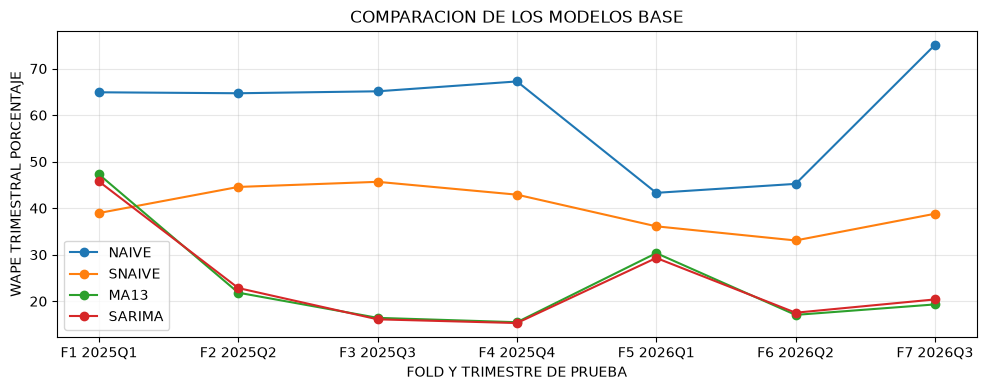

In [16]:
MODELOS_BASE = ["naive", "snaive", "ma13", "sarima"]
NIVELES = {
    "SEMANAL SKU POR CD": ["DC_ID", "SKU_NBR", "ORDER_DATE"],
    "SEMANAL TOTAL": ["ORDER_DATE"],
    "TRIMESTRAL SKU POR CD": ["DC_ID", "SKU_NBR"],
    "TRIMESTRAL SKU": ["SKU_NBR"],
    "TRIMESTRAL TOTAL": [],
}

filas_metricas = []
for fold, datos_fold in fc.groupby("fold"):
    for nivel, llaves in NIVELES.items():
        columnas = ["y"] + MODELOS_BASE
        agregado = datos_fold.groupby(llaves, observed=True)[columnas].sum() if llaves else datos_fold[columnas].sum().to_frame().T
        denominador = agregado["y"].sum()
        for modelo in MODELOS_BASE:
            error = agregado[modelo] - agregado["y"]
            filas_metricas.append({
                "fold": fold,
                "nivel": nivel,
                "modelo": modelo,
                "wape": error.abs().sum() / denominador if denominador else np.nan,
                "sesgo": error.sum() / denominador if denominador else np.nan,
            })

metricas_p2 = pd.DataFrame(filas_metricas)
folds_completos = folds.loc[folds.trimestre_completo, "fold"].tolist()
resumen_completos = (
    metricas_p2[metricas_p2.fold.isin(folds_completos)]
    .groupby(["nivel", "modelo"], as_index=False)[["wape", "sesgo"]]
    .mean()
)
print("PROMEDIO DE LOS TRIMESTRES COMPLETOS")
display(resumen_completos.pivot(index="nivel", columns="modelo", values="wape").round(3))
print("SESGO PROMEDIO DE LOS TRIMESTRES COMPLETOS, POSITIVO ES SOBREPRONOSTICO, ES IGUAL EN TODOS LOS NIVELES")
display(resumen_completos.groupby("modelo")[["sesgo"]].mean().round(3).T)
etiqueta = dict(zip(folds.fold, "F" + folds.fold.astype(str) + " " + folds.trimestre))
print("WAPE Y SESGO TRIMESTRAL SKU POR CD EN CADA FOLD, F7 ES PARCIAL")
display(metricas_p2[metricas_p2.nivel == "TRIMESTRAL SKU POR CD"].assign(fold=lambda d: d.fold.map(etiqueta))
        .pivot_table(index="fold", columns="modelo", values=["wape", "sesgo"]).round(3))

trimestral = metricas_p2[metricas_p2.nivel == "TRIMESTRAL SKU POR CD"]
fig, ax = plt.subplots(figsize=(10, 4))
for modelo in MODELOS_BASE:
    datos = trimestral[trimestral.modelo == modelo]
    ax.plot(datos.fold, datos.wape * 100, marker="o", label=modelo.upper())
ax.set_xticks(folds.fold, [etiqueta[f] for f in folds.fold])
ax.set_xlabel("FOLD Y TRIMESTRE DE PRUEBA")
ax.set_ylabel("WAPE TRIMESTRAL PORCENTAJE")
ax.set_title("COMPARACION DE LOS MODELOS BASE")
ax.legend()
plt.tight_layout()
plt.show()

## QUE PASO EN Q3 DE 2026 (FOLD 7)
- AL SER EL UNICO PERIODO QUE OCURRE TRAS LA CAIDA, SE CONTRASTA LO QUE SE PRONOSTICO CON LO QUE REALMENTE PASO EN LAS 9 SEMANAS.

CAIDA REAL FRENTE A 2025 EN LAS SERIES COMPARADAS -20.4%


,UNIDADES,FRENTE AL REAL
y,2850090.0,0.000
naive,4867551.0,0.708
snaive,3538278.0,0.241
ma13,3200316.0,0.123
sarima,3109466.0,0.091


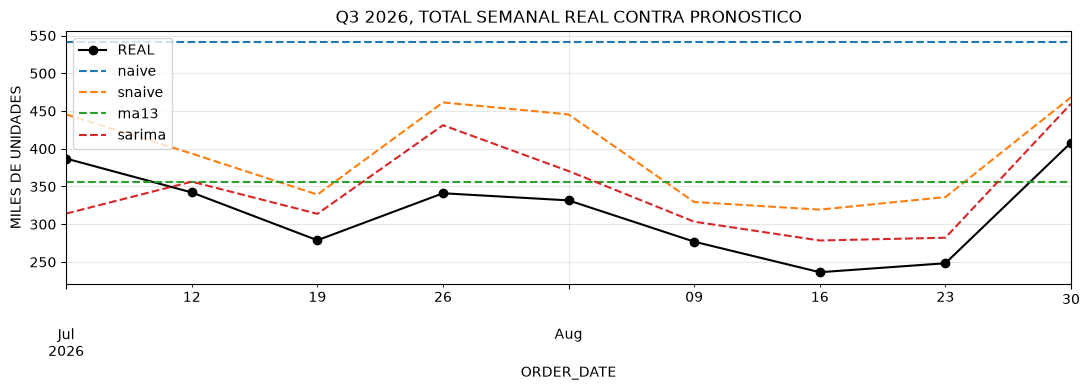

In [17]:
q3 = fc[fc.fold == 7]
real_q3 = q3.groupby(["DC_ID", "SKU_NBR"]).y.sum()
q3_2025 = fc[(fc.fold == 3) & (fc.h <= 9)].groupby(["DC_ID", "SKU_NBR"]).y.sum()       # mismas 9 semanas de 2025
comunes = real_q3.index.intersection(q3_2025.index)
print(f"CAIDA REAL FRENTE A 2025 EN LAS SERIES COMPARADAS {real_q3[comunes].sum() / q3_2025[comunes].sum() - 1:.1%}")

total = q3[["y"] + MODELOS_BASE].sum()
display(pd.DataFrame({"UNIDADES": total.round(0), "FRENTE AL REAL": (total / total["y"] - 1).round(3)}))

semanal = q3.groupby("ORDER_DATE")[["y"] + MODELOS_BASE].sum().rename(columns={"y": "REAL"}) / 1e3
ax = semanal.plot(figsize=(11, 4), style=["k-o"] + ["--"] * len(MODELOS_BASE))
ax.set_ylabel("MILES DE UNIDADES")
ax.set_title("Q3 2026, TOTAL SEMANAL REAL CONTRA PRONOSTICO")
plt.tight_layout()
plt.show()

RESULTADO:
- LA DEMANDA REAL DISMINUYE 20,4 POR CIENTO RESPECTO A LAS MISMAS SEMANAS DE 2025 Y TODOS LOS MODELOS SOBREESTIMAN, NAIVE 70,8 POR CIENTO, NAIVE ESTACIONAL 24,1, MEDIA MOVIL 12,3 Y SARIMA 9,1.
- EL SARIMA ES EL QUE MENOS SOBREESTIMA PORQUE TOMA COMO BASE EL TRIMESTRE PREVIO (DECISION 9), EN CAMBIO EL NAIVE ESTACIONAL REPLICA EL NIVEL DE 2025 Y ESO LO ALEJA DE LO REAL.

LECTURA DE NEGOCIO:
- AUN CON EL MEJOR MODELO BASE SE PIDEN ALREDEDOR DE 260 MIL UNIDADES DE MAS EN 9 SEMANAS, INVENTARIO QUE SE QUEDA SIN MOVERSE EN BODEGA.
- POR ESTA RAZON EL PUNTO 3 SE ENFOCA EN MODELOS QUE INTEGREN EL CALENDARIO DE CIERRES Y EL NIVEL RECIENTE DE CADA SERIE.

## CIERRE DEL PUNTO 2

- PROMEDIO DE LOS FOLDS 1 A 6, QUE VAN DE Q1 2025 A Q2 2026:

| MODELO | WAPE TRIMESTRAL SKU POR CD | WAPE TRIMESTRAL SKU | WAPE TRIMESTRAL TOTAL | SESGO |
|---|---|---|---|---|
| **SARIMA (MEJOR MODELO BASE)** | **24,5** | **21,6** | 11,2 | +5,4 |
| MEDIA MOVIL 13 (METODO ACTUAL) | 24,7 | 22,0 | 12,4 | +5,3 |
| NAIVE ESTACIONAL | 40,2 | 35,0 | 5,0 | +2,1 |
| NAIVE | 58,4 | 56,1 | 51,6 | +51,6 |

- **MEJOR MODELO BASE, EL SARIMA**: SE IMPONE EN SKU POR CD, EN SKU Y EN EL NIVEL SEMANAL, ADEMAS ES EL QUE MENOS SOBREESTIMA EN Q3 DE 2026, SIN EMBARGO SU DIFERENCIA FRENTE A LA MEDIA MOVIL ES MUY CORTA (0,2 PUNTOS EN SKU POR CD).
- EL NAIVE ESTACIONAL OBTIENE EL MEJOR RESULTADO EN EL TOTAL PERO RINDE MAL EN SKU POR CD, YA QUE AL AGREGAR TODAS LAS SERIES SUS ERRORES SE ANULAN ENTRE SI, POR LO TANTO NO ES UTIL PARA DEFINIR CUANTO DESPACHAR A CADA CENTRO.
- EL NAIVE TERMINA SIENDO EL PEOR, DEBIDO A QUE CADA FOLD ARRANCA EN LA SEMANA PICO DE CIERRE Y ESTE MODELO LA COPIA 13 VECES.
- **FOLD 5 = Q1 2026** Y FOLD 1 = Q1 2025 SON LOS DE MAYOR DIFICULTAD, EL MODELO APRENDE HASTA EL CIERRE DE Q4, QUE ES TEMPORADA ALTA, Y TIENE QUE PREDECIR Q1, QUE ES MAS BAJO, LA MEDIA MOVIL Y EL SARIMA ARRASTRAN EL NIVEL DE Q4 Y SOBREESTIMAN (MAS 14,7 Y MAS 13,6 POR CIENTO EN EL FOLD 5), MIENTRAS QUE EL NAIVE ESTACIONAL REPLICA Q1 2025 Y SUBESTIMA (MENOS 8,6) PORQUE Q1 2026 AUMENTO 10 POR CIENTO.

LECTURA DE NEGOCIO:
- LA TRANSICION DE Q4 A Q1 ES EL PUNTO DONDE EL METODO ACTUAL GENERA EL MAYOR RIESGO DE SOBREINVENTARIO.
- EN CONSECUENCIA, UN MODELO AVANZADO TIENE QUE CAPTURAR SIMULTANEAMENTE LA TEMPORADA DEL AÑO Y EL NIVEL RECIENTE.

BENCHMARK:
- **SE DECIDIO QUE EL BENCHMARK DEL PUNTO 3 SEA LA MEDIA MOVIL DE 13 SEMANAS**, CON 24,7 POR CIENTO EN SKU POR CD, 22,0 EN SKU Y 12,4 EN EL TOTAL.
- EL SARIMA SE MANTIENE COMO REFERENCIA EXTRA, Y UN MODELO AVANZADO SOLO SE JUSTIFICA SI SUPERA CON CLARIDAD A AMBOS EN SKU POR CD.

### Punto 3

## MODELOS AVANZADOS

| MODELO | QUE HACE | POR QUE SE ELIGE |
|---|---|---|
| AUTOETS | SUAVIZAMIENTO EXPONENCIAL QUE DA MAYOR PESO A LO MAS RECIENTE Y SELECCIONA PARA CADA SERIE LA TENDENCIA Y LA ESTACIONALIDAD DE 13 SEMANAS (AICc) | SE AJUSTA AL NIVEL RECIENTE, JUSTO LO QUE FALLO EN Q3 2026 |
| LIGHTGBM | ARBOLES QUE SE ENTRENAN CON TODAS LAS SERIES JUNTAS, USANDO VENTAS PREVIAS, MEDIAS MOVILES, MES, fin_mes Y fin_trim | EL PICO DE CIERRE SE LE DA COMO INFORMACION CONOCIDA |
| NHITS | RED NEURONAL GLOBAL QUE OBSERVA LAS 26 SEMANAS MAS RECIENTES DE CADA SERIE Y PREDICE 13, ADEMAS RECIBE fin_mes Y fin_trim | DETECTA PATRONES NO LINEALES |

- SE MANTIENEN LOS MISMOS 7 FOLDS Y LAS MISMAS SERIES DEL PUNTO 2, SIN QUE EL MODELO VEA EL TRIMESTRE DE PRUEBA.
- TODOS LOS PARAMETROS QUEDAN DEFINIDOS ANTES DE LA EVALUACION.
- LIGHTGBM Y NHITS NORMALIZAN LA ESCALA DE CADA SERIE PARA QUE LOS SKU DE MAYOR VOLUMEN NO SE IMPONGAN (DECISION 7).

### DECISION 11, VENTANA DE NHITS
- SE DECIDIO QUE NHITS USE 26 SEMANAS DE ENTRADA (2 TRIMESTRES) PARA PREDECIR 13.
- SI SE USARAN 52, LA VENTANA TOTAL (52 + 13 = 65 SEMANAS) SERIA MAYOR QUE LAS 53 SEMANAS DISPONIBLES EN EL FOLD 1, POR LO QUE LA RED COMPLETARIA CON CEROS Y TERMINARIA SOBREPRONOSTICANDO.
- CON 26 (26 + 13 = 39) LA VENTANA ALCANZA EN TODOS LOS FOLDS, SE TRATA DE UNA CORRECCION POR LA LONGITUD DE LA HISTORIA Y NO DE UN AJUSTE BASADO EN EL TEST.

### DECISION 12, COMBINACION
- SE INCLUYE ADEMAS EL PROMEDIO SIMPLE ENTRE SARIMA, ETS, LIGHTGBM Y NHITS.
- SE DECIDIO NO PONDERAR, PARA EVITAR QUE LOS PESOS SE CALIBREN CON EL TEST.
- COMO CADA MODELO SE EQUIVOCA DE UNA FORMA DISTINTA, AL PROMEDIARLOS SUS ERRORES TIENDEN A COMPENSARSE.

### DECISION 13, COMO SE ELIGE EL GANADOR
- CRITERIO 1, WAPE SEMANAL SKU POR CD, YA QUE EL ENUNCIADO ESTABLECE QUE EL DESEMPEÑO SE EVALUA DE ESA FORMA.
- CRITERIO 2, WAPE TRIMESTRAL SKU POR CD, QUE CORRESPONDE A LA META DEL NEGOCIO, REDUCIR EL ERROR TRIMESTRAL RESPECTO A LA MEDIA MOVIL.
- EL GANADOR DEBE SUPERAR A LA MEDIA MOVIL EN LOS DOS CRITERIOS, Y EN CASO DE QUE NINGUNO LO LOGRE SE PRIORIZA EL TRIMESTRAL.
- EN TODOS LOS CASOS SE TOMA EL PROMEDIO DE LOS FOLDS 1 A 6.

## DECISIONES TOMADAS Y DESCARTADAS

| TEMA | HACEMOS | DESCARTAMOS | POR QUE |
|---|---|---|---|
| VALIDACION | 7 FOLDS CON ORIGEN MOVIL | UN UNICO CORTE USANDO LAS ULTIMAS 13 SEMANAS | UN SOLO TRIMESTRE PUEDE DAR BUEN RESULTADO POR AZAR, CON 6 SE VE SI EL MODELO ES ESTABLE |
| BENCHMARK | MEDIA MOVIL DE 13 SEMANAS | COMPARAR UNICAMENTE FRENTE A SARIMA | EL ENUNCIADO EXIGE SUPERAR EL METODO QUE SE USA HOY |
| SARIMA | ORDEN DEFINIDO CON PRUEBAS, ACF Y AIC | AUTOARIMA AUTOMATICO | SI EL ARIMA SE IDENTIFICA MAL QUEDA PLANO Y CUALQUIER MODELO PARECE BUENO A SU LADO |
| SELECCION | UN SOLO MODELO O COMBINACION PARA TODAS LAS SERIES | ESCOGER EL MEJOR MODELO POR SERIE MIRANDO EL TEST | ESO ES SOBREAJUSTE Y EL ERROR REPORTADO QUEDA MEJOR QUE EL REAL |
| HERRAMIENTAS | STATSFORECAST, MLFORECAST Y NEURALFORECAST CON PARAMETROS DEFINIDOS A MANO | AUTOGLUON Y CHRONOS | FUNCIONAN COMO CAJA NEGRA Y NO PERMITEN EXPLICAR NI CAMBIAR CADA PARAMETRO |
| SERIES CORTAS | ENTRAN A PARTIR DE 26 SEMANAS | QUEDARSE SOLO CON SERIES DE 2 AÑOS | EL NEGOCIO NECESITA PRONOSTICAR TODOS LOS SKU |
| NHITS | VENTANA DE 26 SEMANAS (DECISION 11) | VENTANA DE 52 | NO ALCANZA CON LA HISTORIA DEL FOLD 1 |
| METRICA | SEMANAL Y TRIMESTRAL (DECISION 13) | UNICAMENTE SEMANAL | LO QUE BUSCA EL NEGOCIO ES BAJAR EL ERROR TRIMESTRAL |

In [18]:
import logging, warnings
import lightgbm as lgb
from statsforecast.models import AutoETS
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from mlforecast.target_transforms import LocalStandardScaler
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS
from neuralforecast.losses.pytorch import MAE
for nombre in ["lightning.pytorch", "lightning_fabric", "pytorch_lightning"]:
    logging.getLogger(nombre).setLevel(logging.ERROR)              # oculta los mensajes de entrenamiento de la red
warnings.filterwarnings("ignore", module="pytorch_lightning|neuralforecast")

AVANZADOS = ["ets", "lgbm", "nhits"]
largo[["fin_mes", "fin_trim"]] = marcas_calendario(largo.ds).astype(int).values   # calendario conocido de antemano

ets = StatsForecast(models=[AutoETS(season_length=13, alias="ets")], freq="W-SUN", n_jobs=1)
lgbm = MLForecast(
    models={"lgbm": lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31, objective="l1", random_state=42, verbose=-1)},
    freq="W-SUN",
    lags=[1, 2, 3, 4, 13, 26],                                         # semanas anteriores y mismo punto de 1 y 2 trimestres atras
    lag_transforms={1: [RollingMean(window_size=4), RollingMean(window_size=13)]},
    date_features=["month"],
    target_transforms=[LocalStandardScaler()],                         # escala cada serie con su media y desviacion
)
NHITS_PARAMS = dict(input_size=26,                                    # DECISION 11
                    futr_exog_list=["fin_mes", "fin_trim"], loss=MAE(), scaler_type="robust",
                    max_steps=500, start_padding_enabled=True, random_seed=42, alias="nhits",
                    enable_progress_bar=False, enable_model_summary=False, logger=False)
nhits = NeuralForecast(models=[NHITS(h=13, **NHITS_PARAMS)], freq="W-SUN")

In [19]:
partes = []
for f in folds.itertuples():
    ids = (fc.DC_ID + "_" + fc.SKU_NBR)[fc.fold == f.fold].unique()                  # mismas series del punto 2
    train = largo[largo.unique_id.isin(ids) & (largo.ds <= f.origen)]
    futuro = pd.MultiIndex.from_product([ids, pd.date_range(f.test_inicio, periods=13, freq="W-SUN")], names=["unique_id", "ds"]).to_frame(index=False)
    futuro[["fin_mes", "fin_trim"]] = marcas_calendario(futuro.ds).astype(int).values

    p_ets = ets.forecast(df=train[["unique_id", "ds", "y"]], h=f.n_test)
    lgbm.fit(train[["unique_id", "ds", "y", "fin_mes", "fin_trim"]], static_features=[])
    p_lgbm = lgbm.predict(h=f.n_test, X_df=futuro[futuro.ds <= f.test_fin])
    nhits.fit(train[["unique_id", "ds", "y", "fin_mes", "fin_trim"]], use_init_models=True)   # la red arranca de cero en cada fold
    p_nhits = nhits.predict(futr_df=futuro)

    p = p_ets.merge(p_lgbm, on=["unique_id", "ds"]).merge(p_nhits, on=["unique_id", "ds"])
    assert len(p) == len(ids) * f.n_test, "los pronosticos no cubren todas las series y semanas"
    partes.append(p.assign(fold=f.fold))

av = pd.concat(partes).rename(columns={"ds": "ORDER_DATE"})
av[AVANZADOS] = av[AVANZADOS].clip(lower=0)
fc_todos = fc.assign(unique_id=fc.DC_ID + "_" + fc.SKU_NBR).merge(av, on=["fold", "unique_id", "ORDER_DATE"], validate="one_to_one")
fc_todos["combo"] = fc_todos[["sarima"] + AVANZADOS].mean(axis=1)                  # DECISION 12
print("filas por fold:", fc_todos.groupby("fold").size().to_dict(), "| nulos:", fc_todos[AVANZADOS].isna().sum().sum())

filas por fold: {1: 4537, 2: 4537, 3: 4693, 4: 4693, 5: 4693, 6: 4693, 7: 3267} | nulos: 0


RESULTADO:
- LOS TRES MODELOS GENERAN PRONOSTICO PARA CADA SERIE Y CADA SEMANA DE LOS 7 FOLDS, SIN VALORES NULOS Y CON EXACTAMENTE LAS MISMAS FILAS DE LOS MODELOS BASE.
- EN CONSECUENCIA, LA COMPARACION SE HACE EN IGUALDAD DE CONDICIONES.

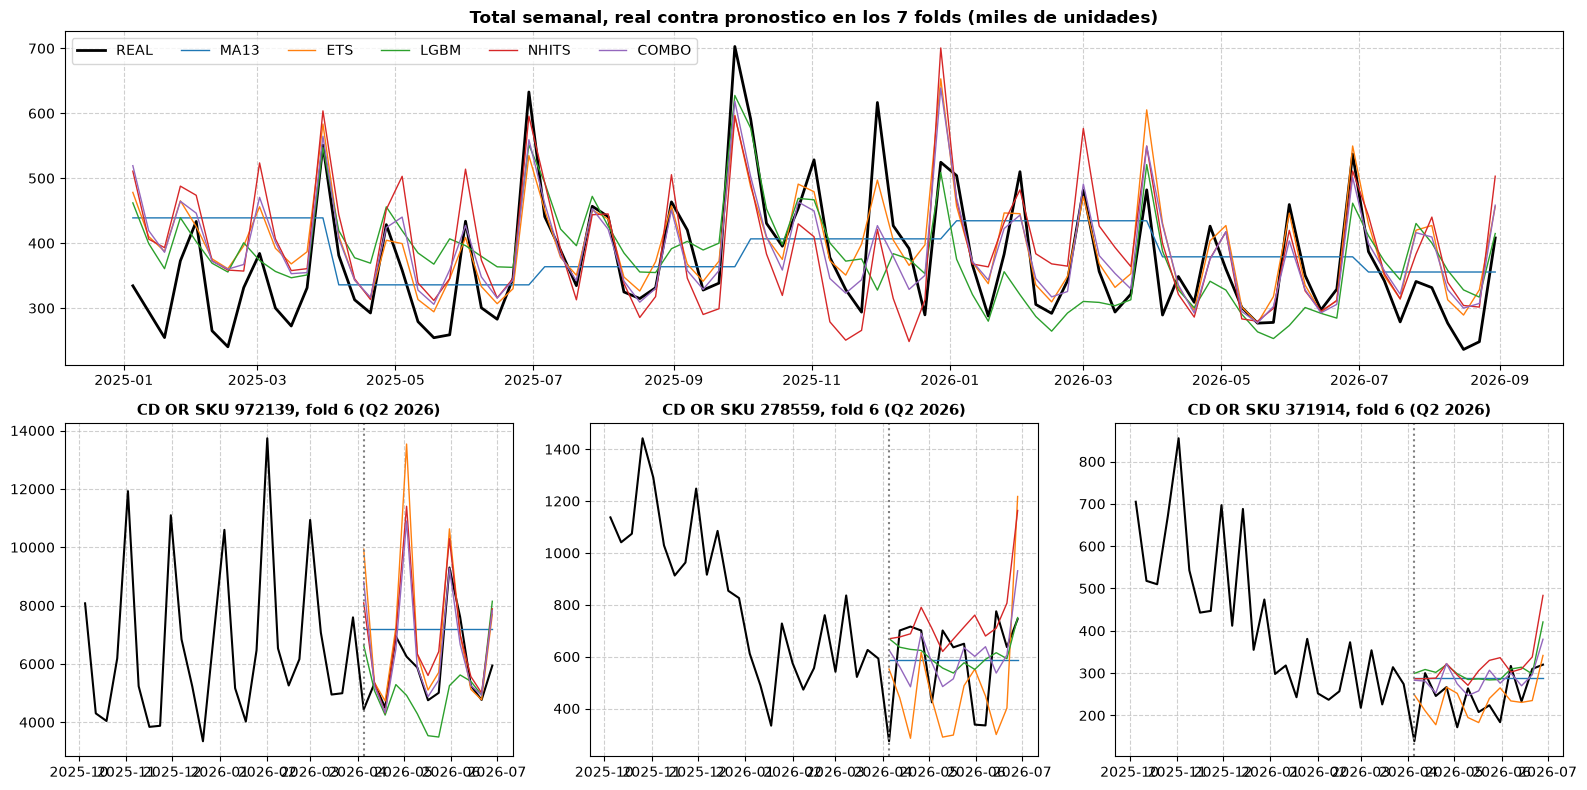

In [20]:
GRAF = ["ma13"] + AVANZADOS + ["combo"]
total_sem = fc_todos.groupby("ORDER_DATE")[["y"] + GRAF].sum() / 1e3
vol = fc_todos[fc_todos.fold == 6].groupby(["DC_ID", "SKU_NBR"]).y.sum().sort_values()
rep = [vol.index[int(len(vol) * q)] for q in (0.98, 0.5, 0.1)]           # series de venta alta, media y baja

fig, ax = plt.subplot_mosaic([["total"] * 3, ["s0", "s1", "s2"]], figsize=(16, 8))
ax["total"].plot(total_sem.y, color="black", lw=2, label="REAL")
for m in GRAF:
    ax["total"].plot(total_sem[m], lw=1, label=m.upper())
ax["total"].set_title("Total semanal, real contra pronostico en los 7 folds (miles de unidades)", fontsize=12, fontweight="bold")
ax["total"].legend(ncol=6)
for i, (dc, sku) in enumerate(rep):
    s = fc_todos[(fc_todos.fold == 6) & (fc_todos.DC_ID == dc) & (fc_todos.SKU_NBR == sku)].set_index("ORDER_DATE")
    previo = panel[(panel.DC_ID == dc) & (panel.SKU_NBR == sku) & (panel.ORDER_DATE <= folds.origen.iloc[5])].set_index("ORDER_DATE").y.tail(26)
    ax[f"s{i}"].plot(pd.concat([previo, s.y]), color="black", lw=1.5)
    for m in GRAF:
        ax[f"s{i}"].plot(s[m], lw=1)
    ax[f"s{i}"].axvline(folds.test_inicio.iloc[5], color="gray", ls=":")
    ax[f"s{i}"].set_title(f"CD {dc} SKU {sku}, fold 6 (Q2 2026)", fontsize=11, fontweight="bold")
for a in ax.values():
    a.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

RESULTADO, CHEQUEO VISUAL:
- TANTO LOS MODELOS AVANZADOS COMO LA COMBINACION REPLICAN LOS PICOS DE CIERRE, EN CAMBIO LA MEDIA MOVIL SE VE PLANA A LO LARGO DEL TRIMESTRE.
- USANDO LA VENTANA DE 26 SEMANAS, NHITS DEJA DE DISPARARSE EN Q1 2025 (DECISION 11).
- A NIVEL DE SERIE, ETS EXAGERA EL PICO EN LA SERIE GRANDE Y LAS CAIDAS EN LA MEDIANA, MIENTRAS QUE LA COMBINACION SE UBICA EN UN PUNTO INTERMEDIO Y MAS PROXIMO A LO REAL.
- LAS FECHAS COINCIDEN, LO QUE CONFIRMA QUE NO HAY FALLAS DE IMPLEMENTACION.

TABLA DE SELECCION, WAPE Y SESGO (%) PROMEDIO DE LOS FOLDS 1 A 6, MEJORA POSITIVA = MEJOR QUE LA MEDIA MOVIL


nivel,SEMANAL SKU POR CD,TRIMESTRAL SKU POR CD,TRIMESTRAL SKU,TRIMESTRAL TOTAL,SESGO,MEJORA SEMANAL,MEJORA TRIMESTRAL
modelo,,,,,,,
naive,65.2,58.4,56.1,51.6,51.6,-27.5,-33.7
snaive,49.0,40.2,35.0,5.0,2.1,-11.3,-15.5
ma13,37.7,24.7,22.0,12.4,5.3,0.0,0.0
sarima,35.7,24.5,21.6,11.2,5.4,2.1,0.3
ets,33.9,25.8,21.7,6.6,6.4,3.9,-1.1
lgbm,35.2,26.7,24.0,10.8,1.8,2.5,-2.0
nhits,32.3,24.7,22.2,12.4,5.9,5.4,0.1
combo,30.2,22.5,19.7,7.7,4.9,7.6,2.3


WAPE TRIMESTRAL SKU POR CD POR FOLD (%)


modelo,ma13,sarima,ets,lgbm,nhits,combo
fold,,,,,,
F1 2025Q1,47.3,45.7,45.2,38.0,45.2,41.8
F2 2025Q2,21.8,22.8,27.3,33.3,26.3,24.9
F3 2025Q3,16.4,16.1,19.5,21.4,17.6,16.1
F4 2025Q4,15.5,15.3,16.9,14.7,18.0,13.3
F5 2026Q1,30.3,29.3,29.1,35.9,25.7,26.2
F6 2026Q2,17.1,17.5,16.9,17.1,15.1,12.5
F7 2026Q3,19.3,20.4,28.1,22.8,24.9,21.5


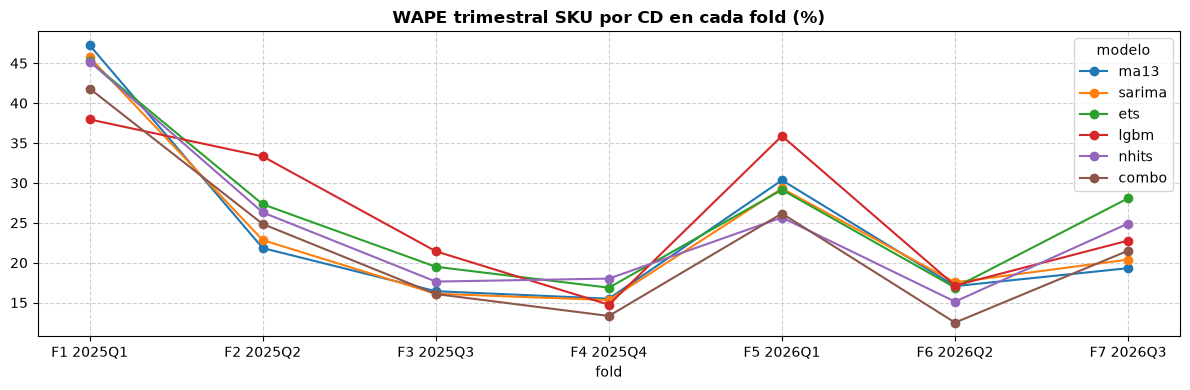

In [21]:
MODELOS = MODELOS_BASE + AVANZADOS + ["combo"]
filas = []
for nivel, llaves in NIVELES.items():
    g = fc_todos.groupby(["fold"] + llaves)[["y"] + MODELOS].sum()
    err, real = g[MODELOS].sub(g.y, axis=0), g.y.groupby("fold").sum()
    filas.append(pd.DataFrame({"wape": err.abs().groupby("fold").sum().div(real, axis=0).stack(),
                               "sesgo": err.groupby("fold").sum().div(real, axis=0).stack(), "nivel": nivel}))
metricas_p3 = pd.concat(filas).rename_axis(["fold", "modelo"]).reset_index()

# tabla de seleccion (DECISION 13), promedio de los folds 1 a 6
completos = metricas_p3[metricas_p3.fold.isin(folds_completos)].groupby(["nivel", "modelo"])[["wape", "sesgo"]].mean()
sel = completos.wape.unstack().loc[["SEMANAL SKU POR CD", "TRIMESTRAL SKU POR CD", "TRIMESTRAL SKU", "TRIMESTRAL TOTAL"], MODELOS].T * 100
sel["SESGO"] = completos.sesgo.unstack().loc["TRIMESTRAL TOTAL", MODELOS] * 100
sel["MEJORA SEMANAL"] = sel.loc["ma13", "SEMANAL SKU POR CD"] - sel["SEMANAL SKU POR CD"]
sel["MEJORA TRIMESTRAL"] = sel.loc["ma13", "TRIMESTRAL SKU POR CD"] - sel["TRIMESTRAL SKU POR CD"]
print("TABLA DE SELECCION, WAPE Y SESGO (%) PROMEDIO DE LOS FOLDS 1 A 6, MEJORA POSITIVA = MEJOR QUE LA MEDIA MOVIL")
display(sel.round(1))

por_fold = metricas_p3[metricas_p3.nivel == "TRIMESTRAL SKU POR CD"].pivot(index="fold", columns="modelo", values="wape")[["ma13", "sarima"] + AVANZADOS + ["combo"]].rename(index=etiqueta) * 100
print("WAPE TRIMESTRAL SKU POR CD POR FOLD (%)")
display(por_fold.round(1))
ax = por_fold.plot(marker="o", figsize=(12, 4))
ax.set_title("WAPE trimestral SKU por CD en cada fold (%)", fontsize=12, fontweight="bold")
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

RESULTADO, PROMEDIO DE LOS FOLDS 1 A 6 (WAPE %):

| MODELO | SEMANAL SKU POR CD | TRIMESTRAL SKU POR CD | TRIMESTRAL TOTAL | SESGO |
|---|---|---|---|---|
| MEDIA MOVIL (ACTUAL) | 37,7 | 24,7 | 12,4 | +5,3 |
| SARIMA | 35,7 | 24,5 | 11,2 | +5,4 |
| ETS | 33,9 | 25,8 | **6,6** | +6,4 |
| LIGHTGBM | 35,2 | 26,7 | 10,8 | **+1,8** |
| NHITS | 32,3 | 24,7 | 12,4 | +5,9 |
| **COMBINACION** | **30,2** | **22,5** | 7,7 | +4,9 |

- CRITERIO 1, SEMANAL: CADA UNO DE LOS AVANZADOS SUPERA A LA MEDIA MOVIL, Y LA COMBINACION LO HACE CON UNA VENTAJA DE 7,6 PUNTOS.
- CRITERIO 2, TRIMESTRAL: UNICAMENTE LA COMBINACION LA SUPERA DE FORMA CLARA, POR 2,3 PUNTOS, MIENTRAS QUE LOS MODELOS POR SEPARADO EMPATAN O QUEDAN POR DEBAJO.
- NHITS ES EL MODELO INDIVIDUAL CON MEJOR RESULTADO SEMANAL (32,3), Y EN EL FOLD 1 SE REDUJO DE 63,3 CON VENTANA DE 52 A 45,2 CON VENTANA DE 26.
- REVISANDO FOLD POR FOLD, LA COMBINACION SE IMPONE EN F1, F4, F5 Y F6, EMPATA EN F3 Y QUEDA POR DEBAJO EN F2 Y EN F7 (Q3 2026, 21,5 FRENTE A 19,3).

LECTURA DE NEGOCIO:
- LOS ERRORES DE CADA MODELO SON DE NATURALEZA DISTINTA, ETS EXAGERA LOS PICOS, NHITS SOBREESTIMA EN SERIES CHICAS Y LIGHTGBM ES EL QUE MENOS SOBREPRONOSTICA.
- AL PROMEDIARLOS ESTOS ERRORES SE CONTRARRESTAN Y LA CIFRA POR CENTRO TERMINA MAS CERCA DE LA REALIDAD.

In [22]:
q = fc_todos[fc_todos.fold.isin(folds_completos)].groupby(["fold", "DC_ID", "SKU_NBR"])[["y"] + MODELOS].sum().reset_index()
q = q.join(info[["abc", "clase"]], on=["DC_ID", "SKU_NBR"])
err = q[MODELOS].sub(q.y, axis=0).abs()
seg = pd.concat({s: err.groupby(q[s], observed=True).sum().div(q.groupby(s, observed=True).y.sum(), axis=0) for s in ["DC_ID", "abc", "clase"]})
seg = (seg[["ma13", "sarima"] + AVANZADOS + ["combo"]] * 100).round(1)
seg["ganador"] = seg.idxmin(axis=1)
print("WAPE TRIMESTRAL SKU POR CD ACUMULADO EN LOS FOLDS 1 A 6, POR SEGMENTO (%)")
display(seg)

WAPE TRIMESTRAL SKU POR CD ACUMULADO EN LOS FOLDS 1 A 6, POR SEGMENTO (%)


ma13  sarima   ets  lgbm  nhits  combo ganador
DC_ID BV            17.4    16.9  18.9  20.4   18.0   15.9   combo
      KC            31.1    30.8  32.4  33.5   31.6   28.2   combo
      MA            23.6    22.8  25.5  21.3   23.2   20.4   combo
      OR            20.4    20.5  21.0  24.6   20.3   19.1   combo
abc   A             23.0    22.8  23.7  25.0   23.0   20.8   combo
      B             28.5    27.9  31.2  31.1   29.0   26.4   combo
      C             30.4    30.0  35.9  32.8   29.2   28.0   combo
clase erratic       38.5    36.1  39.1  51.6   37.0   36.2  sarima
      intermittent  53.6    53.6  71.8  99.6   96.0   69.1    ma13
      smooth        23.1    23.0  24.2  24.4   23.1   20.8   combo

RESULTADO, DONDE GANA CADA MODELO (TRIMESTRAL SKU POR CD):
- LA COMBINACION SE IMPONE EN LOS 4 CDS, EN LAS 3 CLASES ABC Y EN LAS SERIES SMOOTH.
- EL MAYOR AVANCE SE OBSERVA EN KC, CON 28,2 FRENTE A 31,1 DE LA MEDIA MOVIL, QUE ES EL CENTRO MAS COMPLICADO Y EL DE MAYOR CAIDA EN 2026.
- EN LAS 29 SERIES ERRATIC EL SARIMA GANA POR UN MARGEN MINIMO (36,1 FRENTE A 36,2) Y EN LA UNICA SERIE INTERMITTENT LA MEJOR ES LA MEDIA MOVIL.

LECTURA DE NEGOCIO:
- LA MEJORA NO SE EXPLICA POR UN CENTRO EN PARTICULAR NI POR LOS SKU DE MAYOR VOLUMEN, SINO QUE APARECE EN TODOS LOS SEGMENTOS.
- POR ESTO SE CONSIDERA UNA BASE CONFIABLE PARA DISTRIBUIR EL INVENTARIO.

## CIERRE DEL PUNTO 3
- **MODELO GANADOR: COMBINACION, PROMEDIO DE SARIMA, ETS, LIGHTGBM Y NHITS**, SE DECIDIO ELEGIRLO PORQUE ES EL UNICO QUE SATISFACE LOS DOS CRITERIOS DE LA DECISION 13.
- AVANCE FRENTE A LA MEDIA MOVIL: EL SEMANAL SKU POR CD SE REDUCE DE 37,7 A 30,2 Y EL TRIMESTRAL SKU POR CD DE 24,7 A 22,5, LO QUE EQUIVALE A 9 POR CIENTO MENOS DE ERROR TRIMESTRAL.
- PARA EL TOTAL DEL SEGMENTO, EL ERROR TRIMESTRAL DESCIENDE DE 12,4 A 7,7.
- RIESGO: EN Q3 2026 (FOLD 7, PARCIAL) LA MEDIA MOVIL TUVO MEJOR DESEMPEÑO, 19,3 FRENTE A 21,5, POR LO QUE EN EL PUNTO 4 SE HACE SEGUIMIENTO AL SESGO DEL CIERRE DE Q3 Y Q4.
- PARA EL PUNTO 4 SE VUELVEN A ENTRENAR LOS 4 MODELOS CON LA HISTORIA COMPLETA Y SE PROMEDIAN.

### Punto 4

### DECISION 14, PRONOSTICO FINAL
- SE DECIDIO VOLVER A ENTRENAR SARIMA, ETS, LIGHTGBM Y NHITS CON LA HISTORIA COMPLETA (HASTA 2026-08-30) Y LAS 363 SERIES, PARA LUEGO PROMEDIARLOS (DECISION 12).
- EL HORIZONTE CUBRE 17 SEMANAS, DEL 2026-09-06 AL 2026-12-27, ES DECIR 4 SEMANAS PARA TERMINAR Q3 Y 13 PARA Q4.
- NHITS SE INSTANCIA DE NUEVO CON IGUALES PARAMETROS, DADO QUE SU HORIZONTE CAMBIA DE 13 A 17 SEMANAS.
- EL INTERVALO DEL 80 POR CIENTO ES EMPIRICO, SE CALCULA A PARTIR DE LOS ERRORES QUE TUVO LA COMBINACION EN LOS FOLDS 1 A 6 Y NO A PARTIR DE UN SUPUESTO TEORICO.

In [23]:
fechas_fut = pd.date_range(fin + pd.Timedelta(weeks=1), "2026-12-27", freq="W-SUN")   # 2026-09-06 a 2026-12-27
H = len(fechas_fut)
datos = largo[["unique_id", "ds", "y", "fin_mes", "fin_trim"]]
futuro = pd.MultiIndex.from_product([datos.unique_id.unique(), fechas_fut], names=["unique_id", "ds"]).to_frame(index=False)
futuro[["fin_mes", "fin_trim"]] = marcas_calendario(futuro.ds).astype(int).values

p_sarima = sf.forecast(df=datos[["unique_id", "ds", "y"]], h=H)              # mismo SARIMA (1,0,0)(0,1,1)13 del punto 2
p_ets = ets.forecast(df=datos[["unique_id", "ds", "y"]], h=H)
lgbm.fit(datos, static_features=[])
p_lgbm = lgbm.predict(h=H, X_df=futuro)
nhits_final = NeuralForecast(models=[NHITS(h=H, **NHITS_PARAMS)], freq="W-SUN")
nhits_final.fit(datos)
p_nhits = nhits_final.predict(futr_df=futuro)

pron = p_sarima.merge(p_ets, on=["unique_id", "ds"]).merge(p_lgbm, on=["unique_id", "ds"]).merge(p_nhits, on=["unique_id", "ds"])
pron[["sarima"] + AVANZADOS] = pron[["sarima"] + AVANZADOS].clip(lower=0)
pron["combo"] = pron[["sarima"] + AVANZADOS].mean(axis=1)
apagadas = datos.groupby("unique_id").y.apply(lambda s: s.tail(8).sum() == 0)
pron.loc[pron.unique_id.isin(apagadas[apagadas].index), "combo"] = 0      # DECISION 8, sin pedidos en 8 semanas = sin pronostico
pron["ma13"] = pron.unique_id.map(datos.groupby("unique_id").y.apply(lambda s: s.tail(13).mean()))   # metodo actual, para comparar
assert len(pron) == datos.unique_id.nunique() * H and pron.notna().all().all(), "faltan series o semanas"
print(f"series: {pron.unique_id.nunique()} | semanas: {H} ({fechas_fut[0].date()} a {fechas_fut[-1].date()}) | filas: {len(pron)}")

series: 363 | semanas: 17 (2026-09-06 a 2026-12-27) | filas: 6171


RESULTADO:
- SE OBTIENEN 6 171 PRONOSTICOS (363 SERIES POR 17 SEMANAS), SIN VALORES NULOS NI NEGATIVOS.

In [24]:
# intervalo 80%: en el backtest, entre que proporcion del pronostico cayo lo real el 80% de las veces
bt = fc_todos[fc_todos.fold.isin(folds_completos) & (fc_todos.combo > 0)]
banda = (bt.y / bt.combo).quantile([0.1, 0.9]).values
bt_tot = bt.groupby(["fold", "ORDER_DATE"])[["y", "combo"]].sum()
banda_tot = (bt_tot.y / bt_tot.combo).quantile([0.1, 0.9]).values
print(f"serie SKU x CD: lo real cae entre {banda[0]:.2f} y {banda[1]:.2f} veces el pronostico | total: entre {banda_tot[0]:.2f} y {banda_tot[1]:.2f}")
f7 = fc_todos[fc_todos.fold == 7]
print(f"cobertura en el fold 7, que no se uso para calcular la banda: {f7.y.between(f7.combo * banda[0], f7.combo * banda[1]).mean():.0%} de las semanas SKU x CD")

pron[["DC_ID", "SKU_NBR"]] = pron.unique_id.str.split("_", expand=True)
pron["inf_80"], pron["sup_80"] = pron.combo * banda[0], pron.combo * banda[1]
tabla_semanal = pron[["DC_ID", "SKU_NBR", "ds", "combo", "inf_80", "sup_80"]].rename(columns={"ds": "semana", "combo": "pronostico"}).round(0)
print("TABLA SEMANAL POR SKU X CD,", len(tabla_semanal), "FILAS, PRIMERAS 8")
display(tabla_semanal.head(8))

serie SKU x CD: lo real cae entre 0.53 y 1.41 veces el pronostico | total: entre 0.76 y 1.14
cobertura en el fold 7, que no se uso para calcular la banda: 93% de las semanas SKU x CD
TABLA SEMANAL POR SKU X CD, 6171 FILAS, PRIMERAS 8


,DC_ID,SKU_NBR,semana,pronostico,inf_80,sup_80
0,BV,108646,2026-09-06,1323.0,701.0,1869.0
1,BV,108646,2026-09-13,1321.0,699.0,1865.0
2,BV,108646,2026-09-20,1324.0,701.0,1870.0
3,BV,108646,2026-09-27,1739.0,921.0,2456.0
4,BV,108646,2026-10-04,1464.0,775.0,2066.0
5,BV,108646,2026-10-11,1175.0,622.0,1659.0
6,BV,108646,2026-10-18,984.0,521.0,1389.0
7,BV,108646,2026-10-25,1017.0,539.0,1436.0


RESULTADO, INTERVALO DEL 80 POR CIENTO:
- PARA UNA SERIE SKU POR CD, LA DEMANDA REAL SE UBICA ENTRE 0,53 Y 1,41 VECES EL PRONOSTICO, Y PARA EL TOTAL ENTRE 0,76 Y 1,14.
- AL EVALUARLO EN EL FOLD 7, QUE NO SE UTILIZO EN SU CALCULO, CUBRE EL 93 POR CIENTO DE LAS SEMANAS, LO QUE LO HACE CONSERVADOR, UN POCO MAS AMPLIO DE LO NECESARIO.

LECTURA DE NEGOCIO:
- EL PRONOSTICO PUNTUAL SE USA PARA EL PLAN DE DESPACHOS, MIENTRAS QUE EL LIMITE SUPERIOR AYUDA A DEFINIR EL INVENTARIO DE SEGURIDAD.
- A NIVEL DE SERIE LA INCERTIDUMBRE ES ELEVADA, Y A NIVEL TOTAL BASTANTE MENOR, POR ESO ES RECOMENDABLE COMPROMETER EL INVENTARIO DE FORMA CENTRAL Y AJUSTAR LO QUE SE ASIGNA A CADA CENTRO SEMANA A SEMANA.

In [25]:
pron["trimestre"] = pron.ds.dt.to_period("Q").astype(str)
real_q = panel.groupby(["SKU_NBR", "trimestre"]).y.sum().unstack()
pron_q = pron.groupby(["SKU_NBR", "trimestre"])[["combo", "ma13"]].sum().unstack()
cierre = pd.DataFrame({
    "Q3_2025": real_q["2025Q3"], "Q3_2026_real_9sem": real_q["2026Q3"], "Q3_2026_pron_4sem": pron_q["combo", "2026Q3"],
    "Q4_2025": real_q["2025Q4"], "Q4_2026_pron": pron_q["combo", "2026Q4"], "Q4_2026_media_movil": pron_q["ma13", "2026Q4"],
}).fillna(0)
cierre.insert(3, "Q3_2026_cierre", cierre.Q3_2026_real_9sem + cierre.Q3_2026_pron_4sem)
cierre.loc["TOTAL"] = cierre.sum()
cierre["var_Q3_vs_2025_%"] = (cierre.Q3_2026_cierre / cierre.Q3_2025 - 1) * 100
cierre["var_Q4_vs_2025_%"] = (cierre.Q4_2026_pron / cierre.Q4_2025 - 1) * 100
print("CIERRE DEL SEGMENTO (UNIDADES)")
display(cierre.loc[["TOTAL"]].round(1))
print("10 SKU CON MAS VOLUMEN EN Q4 2026")
display(cierre.drop("TOTAL").sort_values("Q4_2026_pron", ascending=False).head(10).round(1))
print("SKU 171322 EN KC, LO QUE PEDIAN LOS MODELOS EN 17 SEMANAS:", round(pron[pron.unique_id == "KC_171322"][["sarima"] + AVANZADOS].mean(axis=1).sum()), "| SE ASIGNA: 0")

CIERRE DEL SEGMENTO (UNIDADES)


,Q3_2025,Q3_2026_real_9sem,Q3_2026_pron_4sem,Q3_2026_cierre,Q4_2025,Q4_2026_pron,Q4_2026_media_movil,var_Q3_vs_2025_%,var_Q4_vs_2025_%
SKU_NBR,,,,,,,,,
TOTAL,5286115.0,2850090.0,1461002.8,4311092.8,5650883.0,4356275.0,4376202.0,-18.4,-22.9


10 SKU CON MAS VOLUMEN EN Q4 2026


,Q3_2025,Q3_2026_real_9sem,Q3_2026_pron_4sem,Q3_2026_cierre,Q4_2025,Q4_2026_pron,Q4_2026_media_movil,var_Q3_vs_2025_%,var_Q4_vs_2025_%
SKU_NBR,,,,,,,,,
910693,493336.0,329379.0,165533.3,494912.3,513316.0,492928.0,497101.0,0.3,-4.0
740537,124435.0,108265.0,53008.8,161273.8,146835.0,164413.6,158706.0,29.6,12.0
571810,218592.0,102242.0,51612.9,153854.9,195792.0,159674.4,152490.0,-29.6,-18.4
888491,164943.0,100836.0,48924.9,149760.9,147314.0,151534.2,148237.0,-9.2,2.9
692270,145088.0,93250.0,47718.4,140968.4,186415.0,146104.3,140142.0,-2.8,-21.6
843837,56171.0,60954.0,36387.0,97341.0,64861.0,101451.5,97127.0,73.3,56.4
336263,122520.0,58335.0,26771.6,85106.6,125356.0,88048.4,80916.0,-30.5,-29.8
147577,74874.0,58867.0,27203.8,86070.8,77002.0,85367.5,86285.0,15.0,10.9
130344,75221.0,49551.0,25410.9,74961.9,88870.0,75936.1,75983.0,-0.3,-14.6


SKU 171322 EN KC, LO QUE PEDIAN LOS MODELOS EN 17 SEMANAS: 987 | SE ASIGNA: 0


RESULTADO, CIERRES DEL SEGMENTO:

| TRIMESTRE | 2025 REAL | 2026 | VARIACION |
|---|---|---|---|
| Q3 | 5,29 M | 4,31 M (2,85 REAL + 1,46 PRONOSTICO) | -18,4 % |
| Q4 | 5,65 M | 4,36 M PRONOSTICO | -22,9 % |

- CON LA MEDIA MOVIL SE OBTENDRIA UN TOTAL PARA Q4 MUY PARECIDO (4,38 M), LA DIFERENCIA REAL ESTA EN DONDE Y CUANDO SE UBICAN LAS UNIDADES, YA QUE LA COMBINACION LAS CONCENTRA EN LAS SEMANAS DE CIERRE Y EN LOS SKU QUE VAN EN CRECIMIENTO.
- DE LOS 10 SKU CON MAS VOLUMEN, CRECEN EL 843837 (+56 POR CIENTO EN Q4) Y EL 740537 (+12), MIENTRAS QUE DISMINUYEN EL 336263 (-30), EL 692270 (-22) Y EL 571810 (-18).
- APLICANDO LA DECISION 8: LOS MODELOS LE DABAN 987 UNIDADES AL SKU 171322 EN KC, PERO SE DECIDIO ASIGNARLE 0 HASTA QUE EL AREA COMERCIAL LO CONFIRME.

LECTURA DE NEGOCIO:
- EN EL S&OP EL SEGUNDO SEMESTRE SE DEBE PLANEAR CON ALREDEDOR DE 20 POR CIENTO MENOS UNIDADES QUE EN 2025.
- EL RIESGO PRINCIPAL NO ESTA EN EL TOTAL, SINO EN DESPACHAR INVENTARIO A LOS SKU QUE VAN EN CAIDA.

In [26]:
real_cd = panel.groupby(["DC_ID", "trimestre"]).y.sum().unstack()
por_cd = pd.DataFrame({"Q4_2025": real_cd["2025Q4"], "Q4_2026_pron": pron[pron.trimestre == "2026Q4"].groupby("DC_ID").combo.sum()})
por_cd["var_%"] = (por_cd.Q4_2026_pron / por_cd.Q4_2025 - 1) * 100
print("Q4 POR CENTRO DE DISTRIBUCION (UNIDADES)")
display(por_cd.round(1))

mes_2025 = panel[panel.trimestre == "2025Q4"].groupby(panel.ORDER_DATE.dt.month).y.sum()
mes_2026 = pron[pron.trimestre == "2026Q4"].groupby(pron.ds.dt.month).combo.sum()
por_mes = pd.DataFrame({"2025_real": mes_2025, "2026_pron": mes_2026}).rename(index={10: "octubre", 11: "noviembre", 12: "diciembre"})
print("Q4 POR MES (UNIDADES)")
display(por_mes.round(0))

Q4 POR CENTRO DE DISTRIBUCION (UNIDADES)


,Q4_2025,Q4_2026_pron,var_%
DC_ID,,,
BV,131054,131860.500,0.6
KC,1686236,1059485.000,-37.2
MA,1396081,1101953.125,-21.1
OR,2437512,2062976.375,-15.4


Q4 POR MES (UNIDADES)

,2025_real,2026_pron
octubre,1870455,1399154.0
noviembre,2145208,1566483.0
diciembre,1635220,1390638.0


RESULTADO, Q4 POR CENTRO Y POR MES:
- KC DISMINUYE 37,2 POR CIENTO, MA 21,1 Y OR 15,4, MIENTRAS QUE BV SE SOSTIENE (+0,6), DE MODO QUE KC CONTINUA SIENDO EL DE MAYOR CAIDA, TAL COMO OCURRIO EN Q3 (PUNTO 1).
- OCTUBRE SIGUE SIENDO EL MES CON MAYOR VENTA POR SEMANA (ALREDEDOR DE 350 MIL SEMANALES, CON DICIEMBRE MUY CERCA), AUNQUE NOVIEMBRE ACUMULA MAS PORQUE CUENTA CON 5 SEMANAS.
- RIESGO: EL MODELO NO RECOGE EL AUMENTO ANUAL DE Q4 SOBRE Q3 (DECISION 4, HISTORIA CORTA), EN 2025 Q4 SUPERO A Q3 EN 6,9 POR CIENTO Y EL PRONOSTICO APENAS MARCA 1 POR CIENTO, SI ESE AUMENTO VUELVE A OCURRIR Q4 PODRIA ACERCARSE A 4,6 M.

LECTURA DE NEGOCIO:
- KC ES EL CENTRO QUE EXIGE MAYOR ATENCION, UNA BAJA DE 37 POR CIENTO ES SIGNIFICATIVA Y LO RECOMENDABLE ES CONFIRMARLA CON COMERCIAL ANTES DE REDUCIR SU INVENTARIO.
- EN BV NO HACE FALTA HACER AJUSTES.

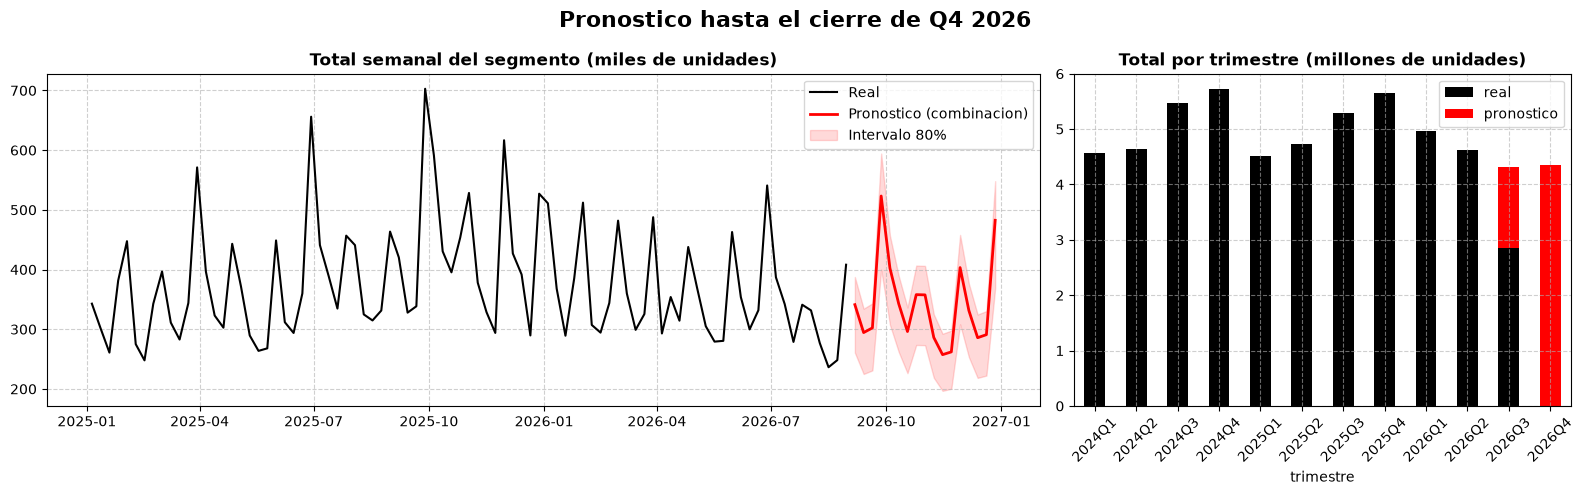

In [27]:
total_real = panel[panel.ORDER_DATE >= "2025-01-01"].groupby("ORDER_DATE").y.sum() / 1e3
total_pron = pron.groupby("ds").combo.sum() / 1e3
por_q = pd.DataFrame({"real": panel.groupby("trimestre").y.sum(), "pronostico": pron.groupby("trimestre").combo.sum()}).fillna(0).loc["2024Q1":] / 1e6

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].plot(total_real, color="black", lw=1.5, label="Real")
axes[0].plot(total_pron, color="red", lw=2, label="Pronostico (combinacion)")
axes[0].fill_between(total_pron.index, total_pron * banda_tot[0], total_pron * banda_tot[1], color="red", alpha=0.15, label="Intervalo 80%")
axes[0].set_title("Total semanal del segmento (miles de unidades)", fontsize=12, fontweight="bold")
axes[0].legend()
por_q.plot.bar(stacked=True, ax=axes[1], color=["black", "red"], rot=45)
axes[1].set_title("Total por trimestre (millones de unidades)", fontsize=12, fontweight="bold")
for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.6)
plt.suptitle("Pronostico hasta el cierre de Q4 2026", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

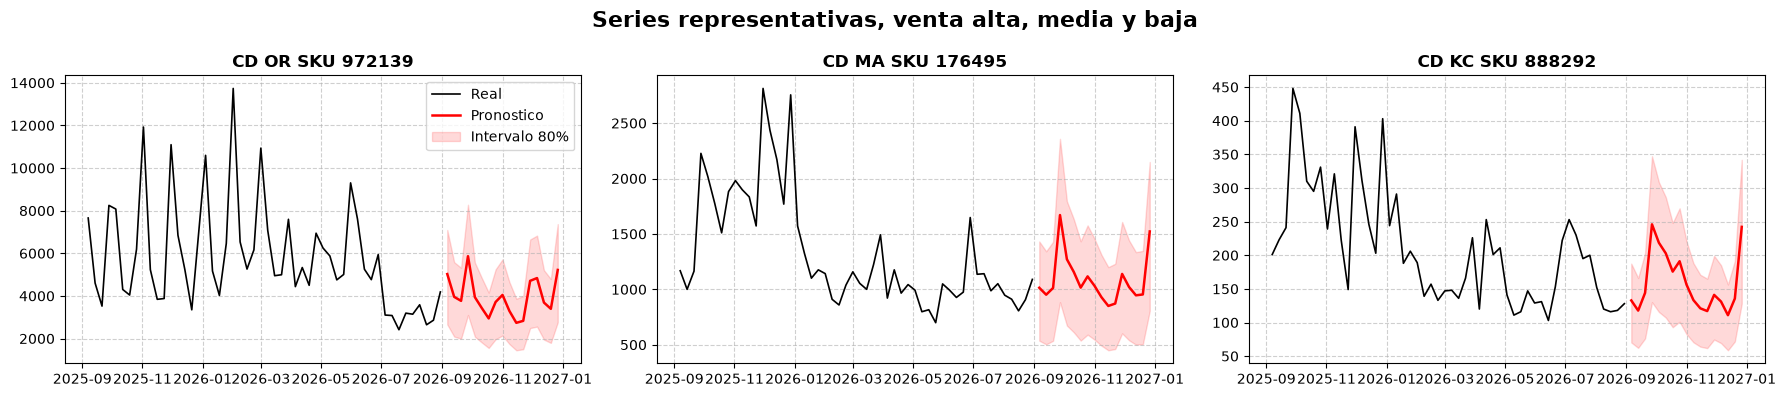

In [28]:
vol = panel.groupby(["DC_ID", "SKU_NBR"]).y.sum().sort_values()
rep = [vol.index[int(len(vol) * q)] for q in (0.98, 0.5, 0.1)]           # series de venta alta, media y baja

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (dc, sku) in zip(axes, rep):
    h = panel[(panel.DC_ID == dc) & (panel.SKU_NBR == sku)].set_index("ORDER_DATE").y.tail(52)
    p = pron[pron.unique_id == f"{dc}_{sku}"].set_index("ds")
    ax.plot(h, color="black", lw=1.2, label="Real")
    ax.plot(p.combo, color="red", lw=1.8, label="Pronostico")
    ax.fill_between(p.index, p.inf_80, p.sup_80, color="red", alpha=0.15, label="Intervalo 80%")
    ax.set_title(f"CD {dc} SKU {sku}", fontsize=12, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.6)
axes[0].legend()
plt.suptitle("Series representativas, venta alta, media y baja", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

RESULTADO, GRAFICAS:
- EL TOTAL VUELVE A MOSTRAR LOS PICOS DE CIERRE DE SEPTIEMBRE Y DICIEMBRE Y SE SOSTIENE EN EL NIVEL REDUCIDO DE 2026, SIN REGRESAR AL DE 2025.
- EN EL GRAFICO DE BARRAS, Q3 Y Q4 DE 2026 SE VEN COMO LOS TRIMESTRES MAS BAJOS DE TODO EL HISTORICO.
- A NIVEL DE SERIE, EL PRONOSTICO REPLICA EL PICO DE CIERRE DE CADA UNA Y EL INTERVALO SE ENSANCHA EN ESAS SEMANAS, QUE SON LAS MAS INCIERTAS.

## MEJORA ESPERADA FRENTE A LA MEDIA MOVIL

| NIVEL | MEDIA MOVIL | COMBINACION | MENOS ERROR |
|---|---|---|---|
| SEMANAL SKU POR CD | 37,7 | 30,2 | 20 % |
| TRIMESTRAL SKU POR CD | 24,7 | 22,5 | 9 % |
| TRIMESTRAL TOTAL | 12,4 | 7,7 | 38 % |

- ESTOS VALORES PROVIENEN DEL BACKTEST DE 6 TRIMESTRES (PUNTO 3) Y NO DE UN PERIODO AISLADO.
- TOMANDO UN Q4 DE 4,36 M UNIDADES, BAJAR 2,2 PUNTOS EL WAPE TRIMESTRAL EQUIVALE A CERCA DE 96 MIL UNIDADES MENOS MAL DISTRIBUIDAS ENTRE CENTROS Y SKU EN CADA TRIMESTRE.

## GUIA PARA REPRODUCIR CADA SEMANA
1. INCORPORAR LA NUEVA SEMANA AL CSV (DOMINGO DE LA SEMANA, DC_ID, SKU_NBR, ITEMS_QTY).
2. EN LA CELDA DE CATALOGO, REVISAR QUE SERIES SON NUEVAS Y CUALES DEJARON DE TENER PEDIDOS (DECISION 8).
3. EN CASO DE QUE CAMBIE EL TRIMESTRE A PLANEAR, AJUSTAR LA FECHA FINAL DENTRO DE `fechas_fut`.
4. CORRER TODO EL NOTEBOOK (ALREDEDOR DE 40 MINUTOS SIN GPU), CON ESTO SE REENTRENAN LOS 4 MODELOS, SE PROMEDIAN Y SE ACTUALIZA EL BACKTEST.
5. CONFIRMAR QUE LA COMBINACION SIGA TENIENDO MENOS ERROR QUE LA MEDIA MOVIL EN LA TABLA DE SELECCION Y QUE LA GRAFICA DEL TOTAL SIGA REPRODUCIENDO LOS PICOS DE CIERRE, NINGUN PARAMETRO SE CAMBIA SIN VOLVER A HACER ESA EVALUACION.

## CONCLUSIONES
- **EN 2026 LA DEMANDA BAJO DE NIVEL**, Q3 TERMINA 18 POR CIENTO Y Q4 23 POR CIENTO POR DEBAJO DE 2025, DE MODO QUE PLANEAR CON BASE EN EL AÑO ANTERIOR LLEVA A SOBREINVENTARIO.
- **EL PICO DEL CIERRE TRIMESTRAL TIENE ORIGEN COMERCIAL Y NO CLIMATICO**, SE PUEDE ANTICIPAR Y LA MEDIA MOVIL NO LO CAPTA.
- **LA COMBINACION DE SARIMA, ETS, LIGHTGBM Y NHITS ES EL MODELO GANADOR**, SUPERA A LA MEDIA MOVIL EN LOS 4 CENTROS Y EN LAS 3 CLASES ABC, REDUCIENDO 20 POR CIENTO EL ERROR SEMANAL Y 9 POR CIENTO EL TRIMESTRAL.
- **NINGUN MODELO FUE SUFICIENTE POR SI SOLO**, CADA UNO SE EQUIVOCA A SU MANERA Y EL PROMEDIO LOS EQUILIBRA, POR ESO SE DECIDIO QUE LA COMBINACION ES MAS ESTABLE QUE DEPENDER DE UN SOLO MODELO.
- **EL RESULTADO ES CONFIABLE**, SE VALIDO EN 6 TRIMESTRES, CON PARAMETROS DEFINIDOS ANTES DE LA EVALUACION Y SIN SELECCIONAR MODELOS POR SERIE MIRANDO LA PRUEBA.
- **LIMITES**: CON SOLO 2,7 AÑOS DE DATOS EL MODELO NO RECOGE EL AUMENTO ANUAL DE Q4 (PODRIA SUBPRONOSTICAR HASTA 6 POR CIENTO), EN Q3 2026 LA MEDIA MOVIL TUVO MEJOR DESEMPEÑO Y LOS LANZAMIENTOS DE FIN DE AÑO NO PUEDEN PREVERSE SIN EL PLAN COMERCIAL.
- **SIGUIENTE PASO**: CONFIRMAR CON EL AREA COMERCIAL LA CAIDA DE KC Y EL CASO DEL SKU 171322, ACTUALIZAR EL PRONOSTICO SEMANALMENTE SIGUIENDO LA GUIA Y, AL COMPLETAR 3 AÑOS DE HISTORIA, INCORPORAR ESTACIONALIDAD ANUAL.